# Project 2: Numerical Integrators For Charged Particles


Amanda Eigner-Avseth, Emilie Klaussen Nygard, Seline Skjølaas Leupi

## Imports

In [106]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from time import perf_counter
from tqdm import tqdm
from scipy.optimize import approx_fprime

## Modelproblems

In [107]:
#2D charged particle
def B_2D(x):
    return np.array([0, 0, np.sqrt(x[0]**2 + x[1]**2)])

#vector potential
def A_2D(x):
    Ax = -x[1]*np.sqrt(x[0]**2 + x[1]**2)
    Ay = x[0]*np.sqrt(x[0]**2 + x[1]**2)
    Az = 0
    return 1/3 * np.array([Ax, Ay, Az])

#electrostatic potential
def U_2D(x):
    return 1/(100*np.sqrt(x[0]**2 + x[1]**2))

#gradient
def grad_U_2D(x):
    Ux = x[0]/((x[0]**2 + x[1]**2)**(3/2))
    Uy = x[1]/((x[0]**2 + x[1]**2)**(3/2))
    Uz = 0
    return -1/100*np.array([Ux, Uy, Uz])

#initial values
x0_2D = np.array([0.0, 1.0, 0.1])
v0_2D = np.array([0.09, 0.05, 0.20])


#Tokamak magnetic field
def B_tokamak(x):
    Bx = -(2*x[1] + x[0]*x[2])/(2*(x[0]**2 + x[1]**2))
    By = (2*x[0] - x[1]*x[2])/(2*(x[0]**2 + x[1]**2))
    Bz = (np.sqrt(x[0]**2 + x[1]**2) - 1)/(2*np.sqrt(x[0]**2 + x[1]**2))
    return np.array([Bx, By, Bz])

#vector potential
def A_tokamak(x):
    Ax = 0
    Ay = 1/2*(x[0] - np.log(np.sqrt(x[0]**2 + x[1]**2) + x[0]))
    Az = -1/2*(x[2]*np.arctan2(x[1], x[0]) + np.log(x[0]**2 + x[1]**2)) #arctan2, in case x[0]<0
    return np.array([Ax, Ay, Az])

#electrostatic potential
def U_tokamak(x):
    return 0

#gradient
def grad_U_tokamak(x):
    return 0

#initial values
x0_tokamak = np.array([1.2, 0.0, 0.0])
v0_tokamak = np.array([0, 4.816e-4, -2.059e-3])

In [108]:
#RHS of ODE
def ODEs(t, y, B, grad_U):
    x = y[:3]
    v = y[3:]
    dxdt = v
    dvdt = np.cross(v, B(x)) - grad_U(x)
    return np.concatenate((dxdt, dvdt))

#energy function
def energy(x, v, U):
    return 0.5*(np.linalg.norm(v, ord=2, axis = 0))**2 + U(x)

#change in energy from time 0
def energy_change(x, v, U):
    return np.abs(energy(x, v, U) - energy(x[:,0], v[:,0], U))

## Implementations of the numerical integration methods

### Boris method

In [109]:
def boris_method(ODEs, x0, v0, h, U, U_grad, B, bool_init,N):
    """
    General Boris method
    """
    #if the initial condition is the actual initial condition (want one step back)
    v_back = v0

    if bool_init: #if we are given (x0,v0)
        t_0 = 0
        t_back = t_0-(h/2)
        t_span = [t_0, t_back]

        initial_condition = np.concatenate((x0,v0))

        sol = solve_ivp(ODEs, t_span, initial_condition, args=(B, U_grad), first_step = (h/2), rtol=1e-10, atol=1e-12)
        v_back = sol.y[3:,-1]
    
    #method implementation
    x_n = x0
    v_n_half = v_back
    
    x_array = np.zeros((3,N)) 
    v_array = np.zeros((3,N))

    start = perf_counter()#measure time

    for i in range(0,N):
        t = h/2*B(x_n)
        s = 2*t / (1 + np.dot(t, t))

        v_minus = v_n_half - (h/2)*U_grad(x_n)
        v_mark = v_minus + np.cross(v_minus, t)
        
        v_pluss = v_minus + np.cross(v_mark,s)

        v_n_pluss_half = v_pluss - (h/2)*U_grad(x_n)
        x_n_pluss_one = x_n + h*v_n_pluss_half

        #update values
        x_n = x_n_pluss_one
        v_n_half = v_n_pluss_half

        #put values into lists for plotting
        x_array[:,i] = x_n
        v_array[:,i] = v_n_half

    end = perf_counter()

    time_spent = end - start
        
    return x_array, v_array, time_spent

### Classical Runge-Kutta 4

In [110]:
#Runge Kutta 4 method
def RK4_step(y_n, h, B, grad_U):
    k_1 = h * ODEs(0, y_n, B, grad_U)
    k_2 = h * ODEs(0, y_n + 0.5*k_1, B, grad_U)
    k_3 = h * ODEs(0, y_n + 0.5*k_2, B, grad_U)
    k_4 = h * ODEs(0, y_n + k_3, B, grad_U)

    return y_n + (k_1 + 2*k_2 + 2*k_3 + k_4)/6

### Fourth order symmetrical multistep method

In [111]:
#find initial values
def starting_values(y0, t_min, t_max, U_grad, B):
    t_vals = np.linspace(t_min, t_max, 8)
    solution = solve_ivp(ODEs,(t_min,t_max) , np.concatenate(y0), args=(B, U_grad), t_eval = t_vals, rtol=1e-12, atol=1e-14, method="DOP853") #y0 must be [x0, v0]
    return solution.y, solution.t

#velocity
def v(x,j, h):
    return delta(x, j)/h

#five point central difference
def delta(y, j):
    return 1/12*(y[:,j-2] - 8*y[:,j-1] + 8*y[:,j+1] - y[:,j+2])

#five point central difference for A(x)
def deltaA(A, x, j):
    return 1/12*(A(x[:,j-2]) - 8*A(x[:,j-1]) + 8*A(x[:,j+1]) - A(x[:,j+2]))

#Fj
def F_j(A, v, U_grad, j, x, h):
    A_jac = np.transpose(approx_fprime(x[:,j], A))
    A_delta = deltaA(A,x, j)/h
    return A_jac@v(x,j,h) - A_delta - U_grad(x[:,j])

#step function
def FOSMM_step(alpha, x , n, h, A, v, U_grad, beta): #find x_(n+4)
    sum = 0
    for j in range(-4, 4):
        sum += alpha[4+j]*x[:,n+j]
    x[:,n+4] = 1/alpha[-1]*(h**2*(beta[1]*F_j(A, v, U_grad,  n-1, x, h) + beta[0]*F_j(A, v, U_grad, n, x, h) + beta[1]*F_j(A, v, U_grad, n+1, x, h))  - sum)

#full multistep method
def FOSMM(alpha, h, A, U_grad,B, beta, T_max, y0): #y0 = [x0, v0]
    N = int(T_max/h) + 1 #number of steps
    start_vals = starting_values(y0, 0, 7*h, U_grad, B) #0 to 7
    x_start = start_vals[0][:3, :]
    v_start = start_vals[0][3:, :]

    x_arr = np.zeros((3,N+2)) #two extra spaces since x_j+2 is needed to find v_j
    v_arr = np.zeros((3,N))

    x_arr[:, :8] = x_start    
    v_arr[:, :8] = v_start

    start = perf_counter() #take time
    for n in range(8, N+2): #evaluate two extra steps in order to find the last value of v
        FOSMM_step(alpha, x_arr, n-4, h, A, v, U_grad, beta)
        v_arr[:,n-2] = v(x_arr, n-2, h)
    stop = perf_counter()
    return x_arr[:, :N], v_arr, stop - start


a = [-0.7, 0.1, 0.9]
beta = [1/3*(20*a[0]*a[1]*a[2]-4*(a[0]*a[1]+a[0]*a[2] + a[1]*a[2])-28*(a[0] + a[1] + a[2])-52), 1/3*(2*a[0]*a[1]*a[2] + 14*(a[0]*a[1] + a[0]*a[2] + a[1]*a[2]) + 26*(a[0]+a[1]+a[2]) + 38)]
alpha = [1, -7/5, 9/25, 22/125, -34/125, 22/125, 9/25, -7/5, 1]

## Task A

#### Parameters and initial conditions

In [112]:
#parameters for task A
T_A = 1e5
h_A = 0.1
N_A = int(T_A/h_A) #number of time steps
t_A = np.linspace(0, T_A, N_A + 1)
t_A_boris = t_A[1:]

#initial conditions as one vector
y0_2D = np.concatenate((x0_2D, v0_2D))
y0_tok = np.concatenate((x0_tokamak, v0_tokamak))

#FOSMM takes the initial condition as a 2x3 array
y0_FOSMM_2D = np.array([x0_2D, v0_2D])
y0_FOSMM_tok = np.array([x0_tokamak, v0_tokamak])

#### Computations for Boris

In [113]:
#Boris method
x_boris_2D, v_boris_2D, _ = boris_method(ODEs, x0_2D, v0_2D, h_A, U_2D, grad_U_2D, B_2D, True, N_A)

x_boris_tok, v_boris_tok, _ = boris_method(ODEs, x0_tokamak, v0_tokamak, h_A, U_tokamak, grad_U_tokamak, B_tokamak, True, N_A)

R_boris_tok = np.sqrt(x_boris_tok[0]**2 + x_boris_tok[1]**2)
z_boris_tok = x_boris_tok[2]

#### Computations for RK4

In [114]:
#RK4, 2D particle
y_RK4_2D = np.zeros((N_A + 1, 6))
y_RK4_2D[0] = y0_2D

y_n = y0_2D.copy()
for i in tqdm(range(N_A)):
    y_n = RK4_step(y_n, h_A, B_2D, grad_U_2D) #update array
    y_RK4_2D[i+1] = y_n

x_RK4_2D = y_RK4_2D[:, :3] #positions
v_RK4_2D = y_RK4_2D[:, 3:] #velocity

100%|██████████| 1000000/1000000 [00:55<00:00, 17960.20it/s]


In [115]:
#RK4, Tokamak field
y_RK4_tok = np.zeros((N_A + 1, 6))
y_RK4_tok[0] = y0_tok

y_n = y0_tok.copy()
for i in tqdm(range(N_A)):
    y_n = RK4_step(y_n, h_A, B_tokamak, grad_U_tokamak)
    y_RK4_tok[i+1] = y_n

x_RK4_tok = y_RK4_tok[:, :3] #position
v_RK4_tok = y_RK4_tok[:, 3:] #velocity

100%|██████████| 1000000/1000000 [00:57<00:00, 17445.58it/s]


In [116]:
#computing R,z for plotting Tokamak trajectory
R_RK4_tok = np.sqrt(x_RK4_tok[:, 0]**2 + x_RK4_tok[:, 1]**2)
z_RK4_tok = x_RK4_tok[:, 2]

#### Computations for Fourth order symmetric multistep method (further on refered to as FOSMM)

In [117]:
#Fourth order symmetric multistep method (FOSMM)
x_FOSMM_2D, v_FOSMM_2D, _ = FOSMM(alpha, h_A, A_2D, grad_U_2D, B_2D, beta, T_A, y0_FOSMM_2D) #solve with FOSMM for 2D particle

x_FOSMM_tok, v_FOSMM_tok, _ = FOSMM(alpha, h_A, A_tokamak, grad_U_tokamak, B_tokamak, beta, T_A, y0_FOSMM_tok) #solve with FOSMM for tokamak field

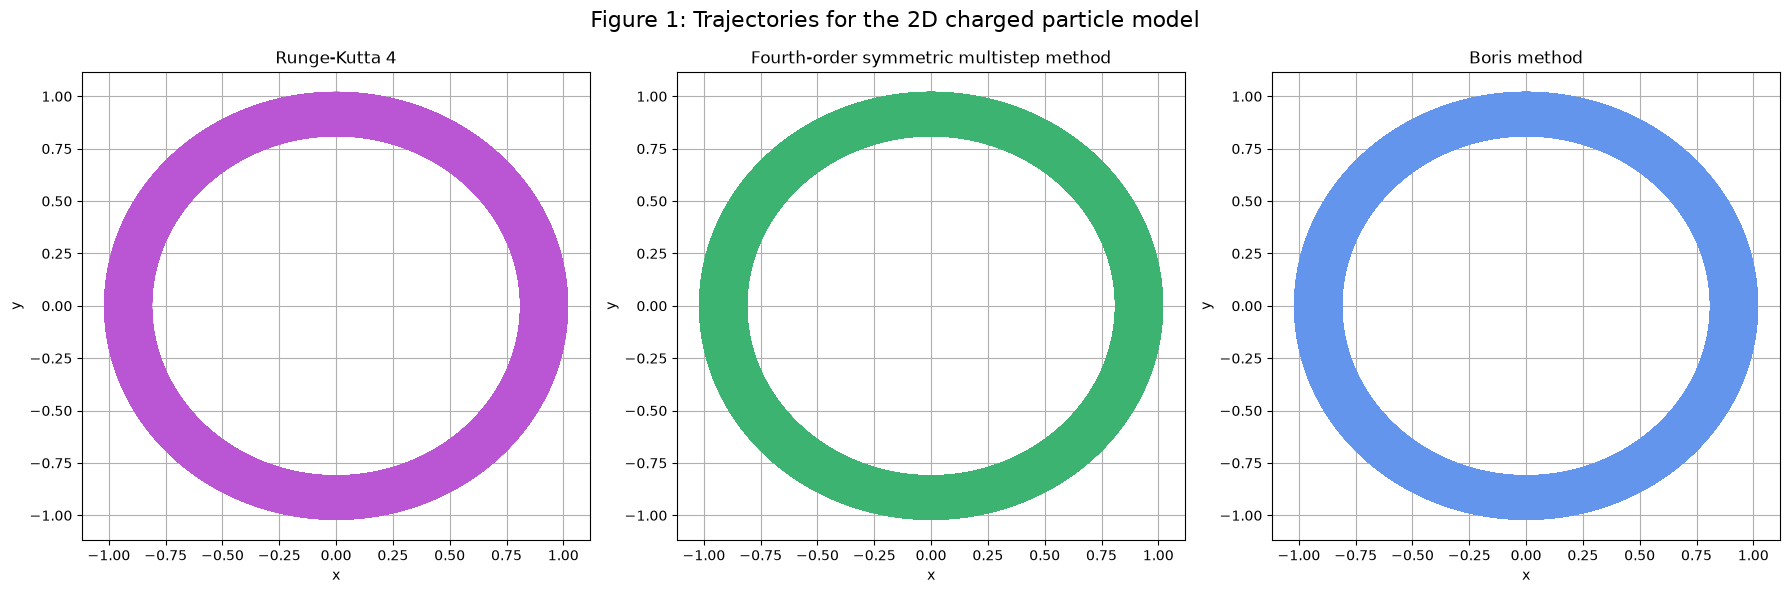

In [118]:
#plotting trajectories in xy-plane for 2d particle
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle("Figure 1: Trajectories for the 2D charged particle model", fontsize=16)

#RK4
axes[0].plot(x_RK4_2D[:, 0], x_RK4_2D[:, 1], color='mediumorchid', label='x1')
axes[0].set_xlabel('x')
axes[0].set_ylabel('y')
axes[0].set_title('Runge-Kutta 4')
axes[0].grid(True)

#FOSMM
axes[1].plot(x_FOSMM_2D[0, :], x_FOSMM_2D[1, :], color="mediumseagreen")
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
axes[1].set_title("Fourth-order symmetric multistep method")
axes[1].grid(True)

#Boris
axes[2].plot(x_boris_2D[0], x_boris_2D[1], label="trajectory", color="cornflowerblue")
axes[2].set_xlabel("x")
axes[2].set_ylabel("y")
axes[2].set_title("Boris method")
axes[2].grid(True)

plt.tight_layout()
plt.show()

In figure 1, we have plotted the trajectories of the 2D charged particles in the xy-plane, and observe the expected circular trajectories. All methods provide the same trajectory.

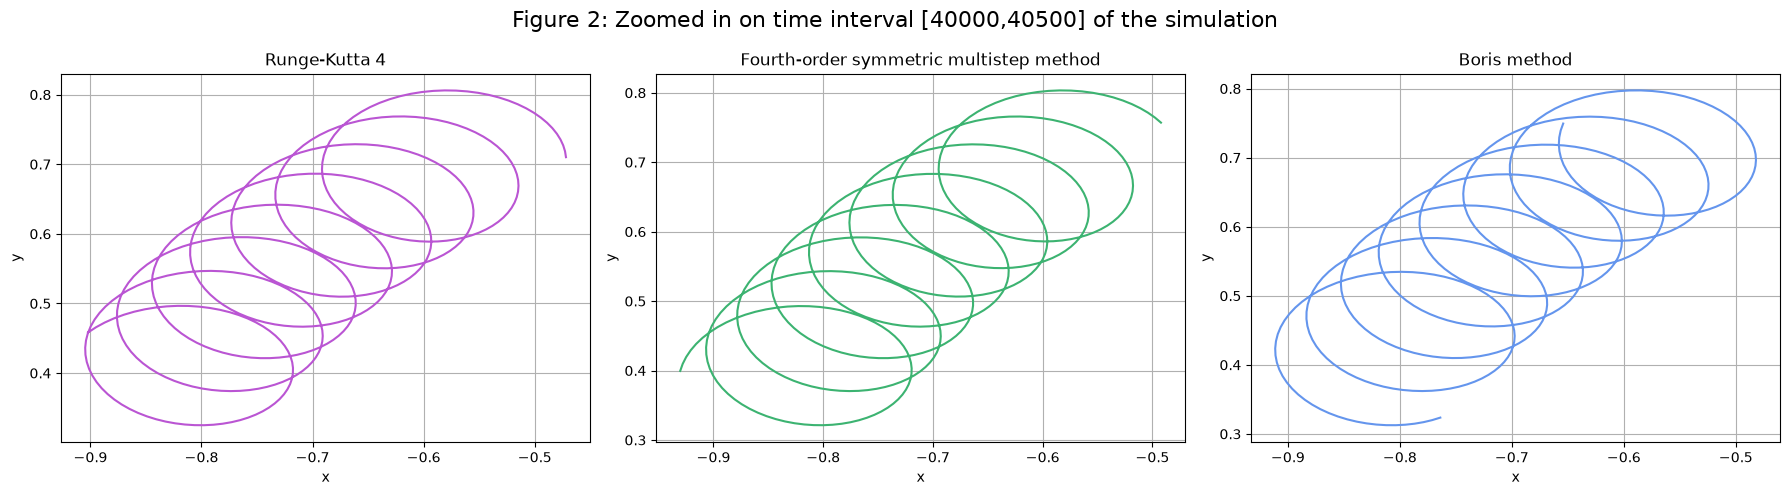

In [119]:
#zoomed in plots over a smaller time interval
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].plot(x_RK4_2D[:, 0][40000:40500], x_RK4_2D[:, 1][40000:40500], color='mediumorchid', label='x1')
axes[0].set_xlabel('x')
axes[0].set_ylabel('y')
axes[0].set_title('Runge-Kutta 4')
axes[0].grid(True)

#FOSMM
axes[1].plot(x_FOSMM_2D[0, :][40000:40500], x_FOSMM_2D[1, :][40000:40500], color="mediumseagreen")
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
axes[1].set_title("Fourth-order symmetric multistep method")
axes[1].grid(True)

#Boris
axes[2].plot(x_boris_2D[0][40000:40500], x_boris_2D[1][40000:40500], label="trajectory", color="cornflowerblue")
axes[2].set_xlabel("x")
axes[2].set_ylabel("y")
axes[2].set_title("Boris method")
axes[2].grid(True)

for ax in axes:
    ax.grid(True)

fig.suptitle("Figure 2: Zoomed in on time interval [40000,40500] of the simulation", fontsize=16)
plt.tight_layout()
plt.show()

In figure 2, we have zoomed in on a time interval of 500 steps, to better see the motion of the particle. We observe a helix-like motion from each method, and at a given time we can see that the particle is not necessarily at the same point in space for the different methods. In other words, we observe a form of delay between the method.

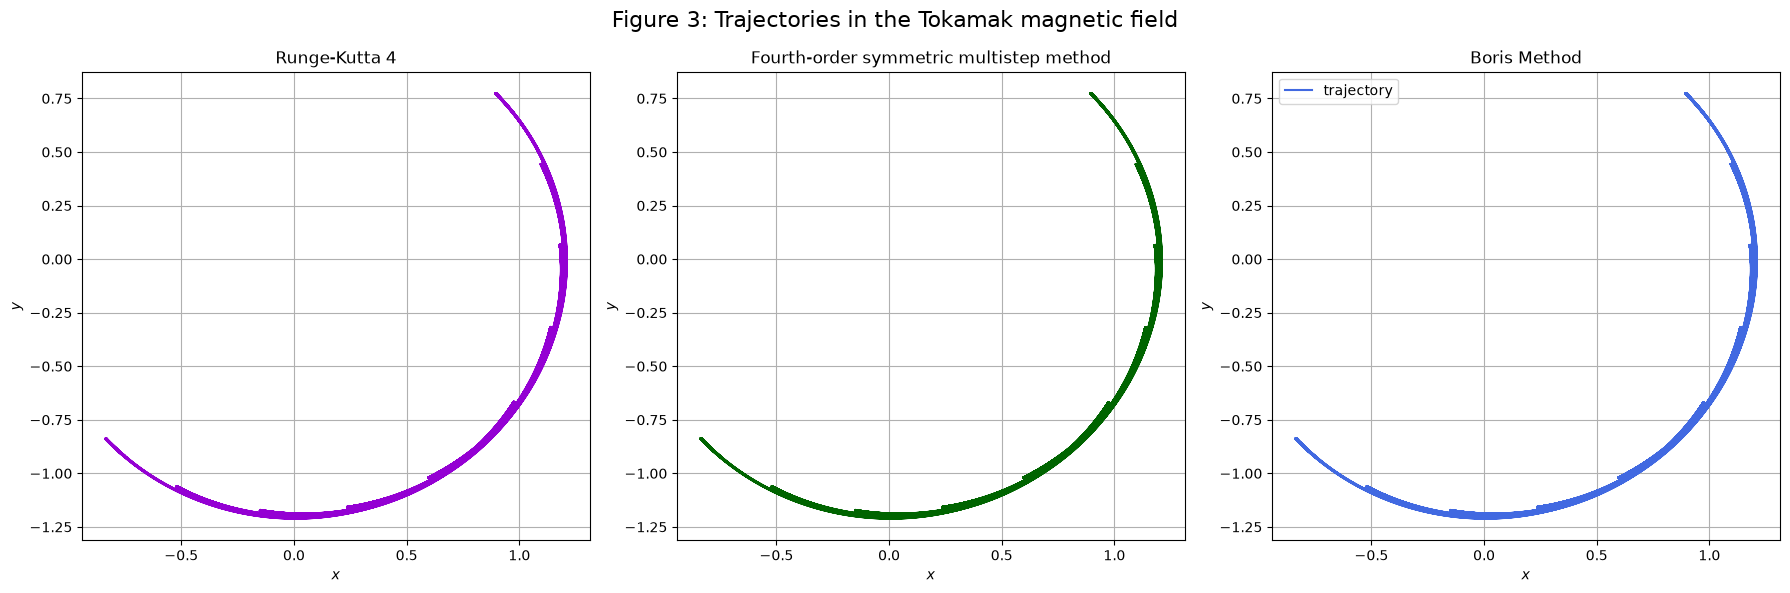

In [120]:
#plottting tokamak field trajectories in xy-plane
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

#RK4
axes[0].plot(x_RK4_tok[:, 0], x_RK4_tok[:, 1], color="darkviolet")
axes[0].set_xlabel(r"$x$")
axes[0].set_ylabel(r"$y$")
axes[0].set_title("Runge-Kutta 4")
axes[0].grid(True)

#FOSMM
axes[1].plot(x_FOSMM_tok[0, :], x_FOSMM_tok[1, :], color="darkgreen")
axes[1].set_xlabel(r"$x$")
axes[1].set_ylabel(r"$y$")
axes[1].set_title("Fourth-order symmetric multistep method")
axes[1].grid(True)

#Boris
axes[2].plot(x_boris_tok[0], x_boris_tok[1], label="trajectory", color="royalblue")
axes[2].set_xlabel(r"$x$")
axes[2].set_ylabel(r"$y$")
axes[2].set_title("Boris Method")
axes[2].legend()
axes[2].grid(True)

fig.suptitle("Figure 3: Trajectories in the Tokamak magnetic field", fontsize=16)
plt.tight_layout()
plt.show()

In figure 3, we observe a half-moon shape of the trajectory of the Tokamak magnetic field model in the xy-plane. Again all numerical methods provide the same shape of the trajectory.

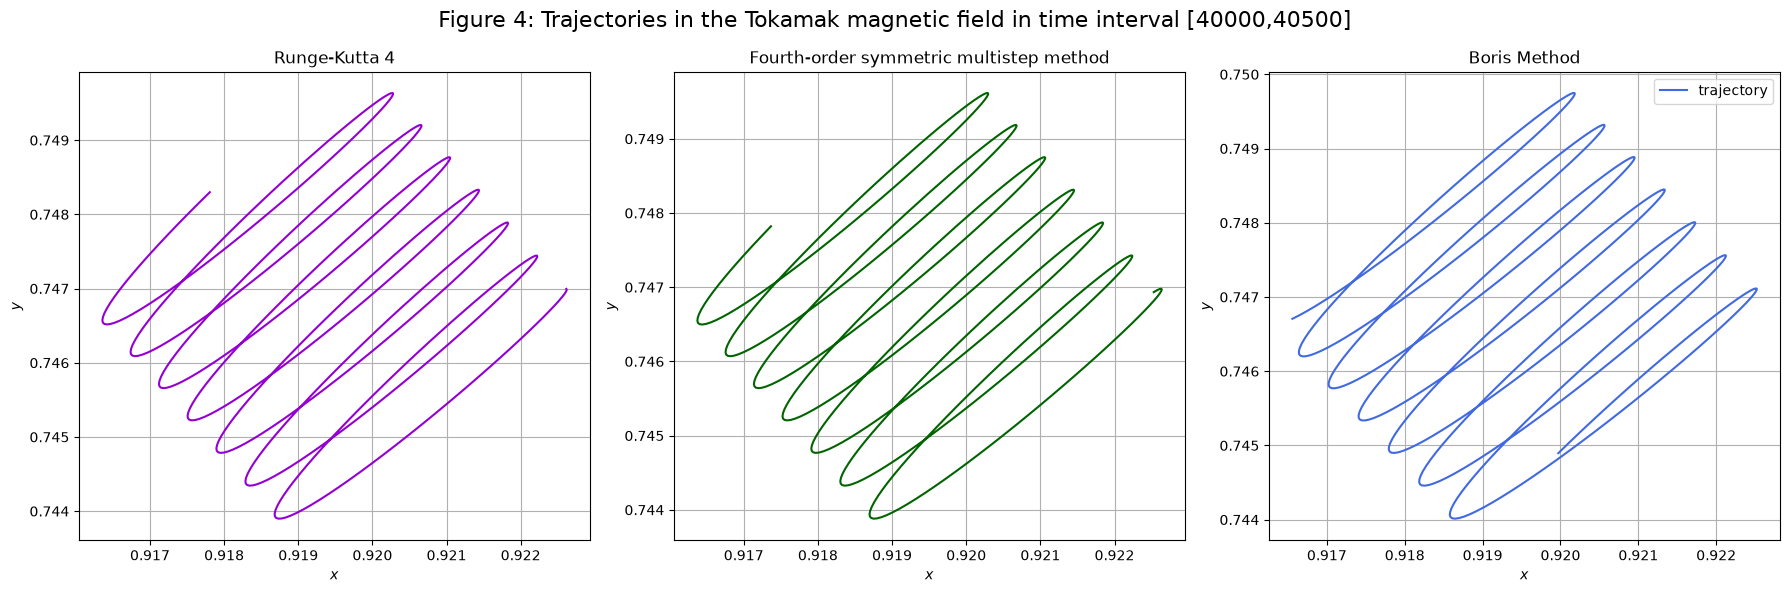

In [121]:
#Zoom in on smaller time interval
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

#RK4
axes[0].plot(x_RK4_tok[:, 0][40000:40500], x_RK4_tok[:, 1][40000:40500], color="darkviolet")
axes[0].set_xlabel(r"$x$")
axes[0].set_ylabel(r"$y$")
axes[0].set_title("Runge-Kutta 4")
axes[0].grid(True)

#FOSMM
axes[1].plot(x_FOSMM_tok[0, :][40000:40500], x_FOSMM_tok[1, :][40000:40500], color="darkgreen")
axes[1].set_xlabel(r"$x$")
axes[1].set_ylabel(r"$y$")
axes[1].set_title("Fourth-order symmetric multistep method")
axes[1].grid(True)

#Boris
axes[2].plot(x_boris_tok[0][40000:40500], x_boris_tok[1][40000:40500], label="trajectory", color="royalblue")
axes[2].set_xlabel(r"$x$")
axes[2].set_ylabel(r"$y$")
axes[2].set_title("Boris Method")
axes[2].legend()
axes[2].grid(True)

fig.suptitle("Figure 4: Trajectories in the Tokamak magnetic field in time interval [40000,40500]", fontsize=16)
plt.tight_layout()
plt.show()

Once more we plot a zoomed in version of the trajectory. From figure 4 we can notice a similar delay as for the 2D magnetic field, for the Tokamak magnetic field model.

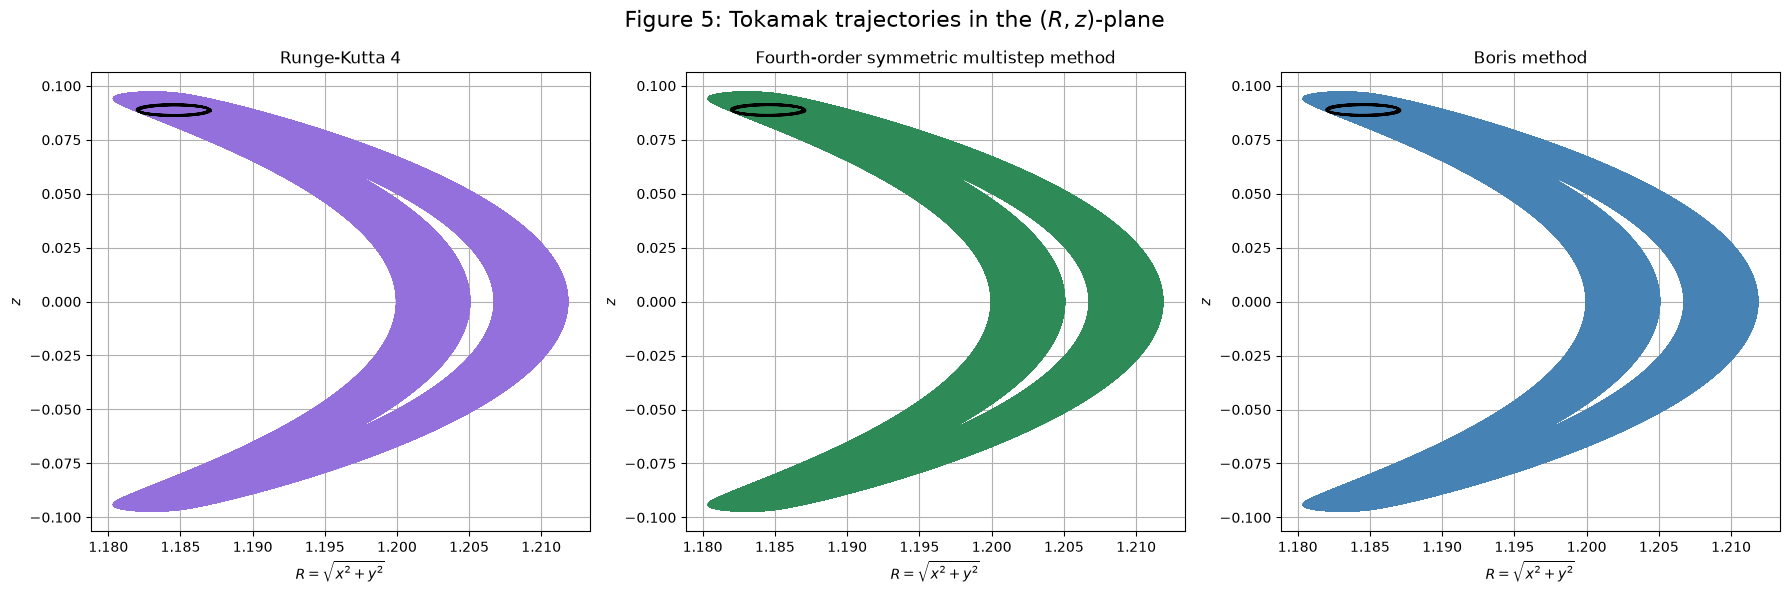

In [122]:
#tokamak trajectories in Rz-plane
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

#RK4
axes[0].plot(R_RK4_tok, z_RK4_tok, color="mediumpurple")
axes[0].set_xlabel(r"$R=\sqrt{x^2+y^2}$")
axes[0].set_ylabel(r"$z$")
axes[0].set_title("Runge-Kutta 4")
axes[0].grid(True)

#FOSMM
axes[1].plot(np.sqrt(x_FOSMM_tok[0, :]**2 + x_FOSMM_tok[1, :]**2), x_FOSMM_tok[2, :], color="seagreen")
axes[1].set_xlabel(r"$R=\sqrt{x^2+y^2}$")
axes[1].set_ylabel(r"$z$")
axes[1].set_title("Fourth-order symmetric multistep method")
axes[1].grid(True)


#Boris
axes[2].plot(R_boris_tok, z_boris_tok, color="steelblue")
axes[2].set_xlabel(r"$R=\sqrt{x^2+y^2}$")
axes[2].set_ylabel(r"$z$")
axes[2].set_title("Boris method")
axes[2].grid(True)


#plotting smaller time interval
#RK4
axes[0].plot(R_RK4_tok[40000:40500], z_RK4_tok[40000:40500], color="black", label = "zoomed in")
axes[0].set_xlabel(r"$R=\sqrt{x^2+y^2}$")
axes[0].set_ylabel(r"$z$")
axes[0].set_title("Runge-Kutta 4")
axes[0].grid(True)

#FOSMM
axes[1].plot(np.sqrt(x_FOSMM_tok[0, :]**2 + x_FOSMM_tok[1, :]**2)[40000:40500], x_FOSMM_tok[2, :][40000:40500], color="black")
axes[1].set_xlabel(r"$R=\sqrt{x^2+y^2}$")
axes[1].set_ylabel(r"$z$")
axes[1].set_title("Fourth-order symmetric multistep method")
axes[1].grid(True)


#Boris
axes[2].plot(R_boris_tok[40000:40500], z_boris_tok[40000:40500], color="black")
axes[2].set_xlabel(r"$R=\sqrt{x^2+y^2}$")
axes[2].set_ylabel(r"$z$")
axes[2].set_title("Boris method")
axes[2].grid(True)


fig.suptitle("Figure 5: Tokamak trajectories in the $(R, z)$-plane", fontsize=16)
plt.tight_layout()
plt.show()

Figure 5 displays the trajecotry in the Rz-plane, we see that the movement of the particle is contained within a certain region of space following a banana orbit similar to the one in article 3. All methods provide the same trajectory. 

The black circles represent the zoomed in areas in the next figure.

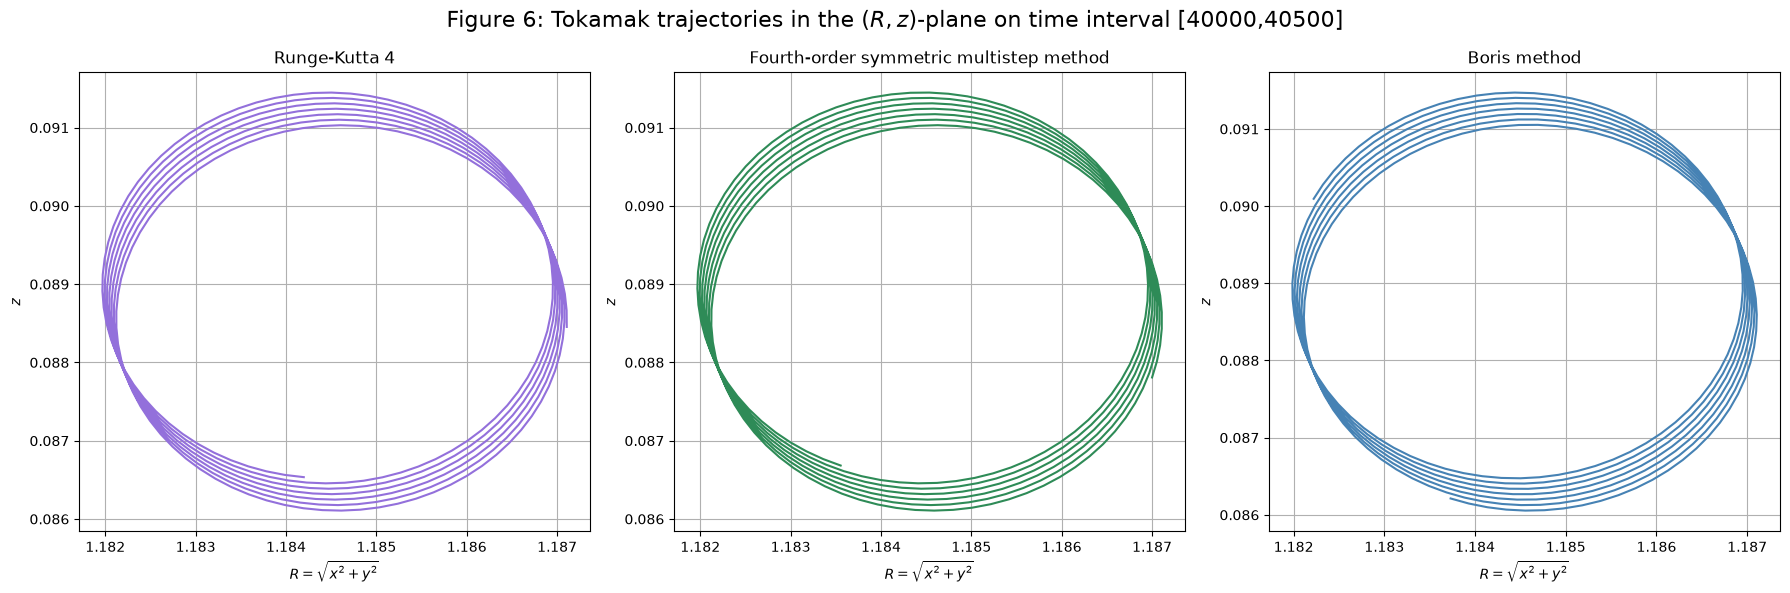

In [123]:
#Zooomed in on smaller interval (marked black in last figure)
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

#RK4
axes[0].plot(R_RK4_tok[40000:40500], z_RK4_tok[40000:40500], color="mediumpurple")
axes[0].set_xlabel(r"$R=\sqrt{x^2+y^2}$")
axes[0].set_ylabel(r"$z$")
axes[0].set_title("Runge-Kutta 4")
axes[0].grid(True)

#FOSMM
axes[1].plot(np.sqrt(x_FOSMM_tok[0, :]**2 + x_FOSMM_tok[1, :]**2)[40000:40500], x_FOSMM_tok[2, :][40000:40500], color="seagreen")
axes[1].set_xlabel(r"$R=\sqrt{x^2+y^2}$")
axes[1].set_ylabel(r"$z$")
axes[1].set_title("Fourth-order symmetric multistep method")
axes[1].grid(True)


#Boris
axes[2].plot(R_boris_tok[40000:40500], z_boris_tok[40000:40500], color="steelblue")
axes[2].set_xlabel(r"$R=\sqrt{x^2+y^2}$")
axes[2].set_ylabel(r"$z$")
axes[2].set_title("Boris method")
axes[2].grid(True)


fig.suptitle("Figure 6: Tokamak trajectories in the $(R, z)$-plane on time interval [40000,40500]", fontsize=16)
plt.tight_layout()
plt.show()

Once more, in figure 6, we witness a delay between the methods when only looking at a small interval. 

### Reference solutions for task A

In [124]:
#solving with scipy.solve_ivp to find a reference solution of high accuracy
sol_A_2D = solve_ivp(ODEs, (0, T_A), y0_2D,
                     args=(B_2D, grad_U_2D),
                     method="DOP853", rtol=1e-12, atol=1e-14, t_eval=t_A)

sol_A_tok = solve_ivp(ODEs, (0, T_A), y0_tok,
                      args=(B_tokamak, grad_U_tokamak),
                      method="DOP853", rtol=1e-12, atol=1e-14, t_eval=t_A)

### Error for Boris

In [125]:
#Boris stores x at times h, ..., T, so we compare with the reference from time h (instead of 0)
err_boris_2D = np.linalg.norm(x_boris_2D - sol_A_2D.y[:3, 1:], axis = 0, ord = 2)
err_boris_tok = np.linalg.norm(x_boris_tok - sol_A_tok.y[:3, 1:], axis = 0, ord = 2)

### Error for RK4

In [126]:
#transposing RK4 solution to make the shapes work: x_RK4 has shape (N+1, 3), the others(3, N+1)
err_RK4_2D = np.linalg.norm(x_RK4_2D - sol_A_2D.y[:3, :].T, axis = 1)
err_RK4_tok = np.linalg.norm(x_RK4_tok - sol_A_tok.y[:3, :].T, axis = 1)

### Error for FOSMM

In [127]:
#computing error from reference solution
def error(x, xref): 
    return np.linalg.norm(x-xref, ord=2, axis = 0)

err_FOSMM_2D = error(x_FOSMM_2D, sol_A_2D.y[:3])
err_FOSMM_tok = error(x_FOSMM_tok, sol_A_tok.y[:3])

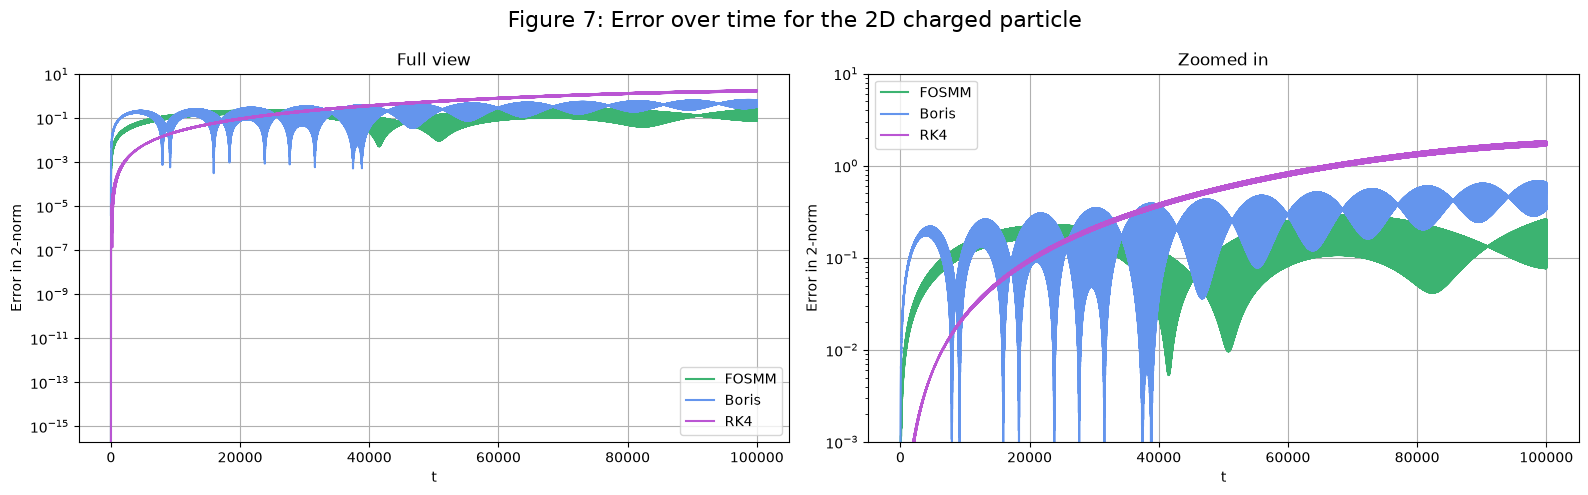

''

In [128]:
#error for 2d particle using all three methods

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax in axes:
    ax.semilogy(np.linspace(0, T_A, len(err_FOSMM_2D)), err_FOSMM_2D, color='mediumseagreen', label='FOSMM')
    ax.semilogy(t_A_boris, err_boris_2D, color='cornflowerblue', label='Boris')
    ax.semilogy(t_A, err_RK4_2D, color='mediumorchid', label='RK4')
    ax.set_xlabel('t')
    ax.set_ylabel('Error in 2-norm')
    ax.legend()
    ax.grid(True)

axes[0].set_title('Full view')
axes[1].set_title('Zoomed in')
axes[1].set_ylim(1e-3, 1e1)

fig.suptitle('Figure 7: Error over time for the 2D charged particle', fontsize=16)
plt.tight_layout()
plt.show()
;

A plot of the error in 2-norm in positions compared to those of the reference solutions are shown in figure 7. RK4 starts out with a smaller error than the two other numerical methods, however, over time the RK4 method accumulates more error than the other two methods. 

In article 3, they refer to another article; Efficiency of a Boris like Integration Scheme with Spatial Stepping. The article explains that although the Boris method is effective at preserving conserved quantities, it is still only a second-order integration scheme and therefore introduces numerical errors. In particluar, the scheme can introduce a phase error, causing the numerical trajectory to rotate slightly slower or faster than the reference trajectory. This phase difference accumulates over time and leads to an increasing position error in the 2-norm, even though the method preserves the orbit’s radius and energy well. Although the cited article considers a spatial-Boris scheme, the same general expansion in terms of phase error can still be relevant to the time-staggered Boris method used in this task. 

Perhaps the weird shaped bulk-like phenomenon for the FOSMM is a similar phenomenon, with a smaller phase error, leading to a longer segment of colored area in the plot. The rapid oscillations cause the areas to appear almost solid for the Boris and FOSMM methods.

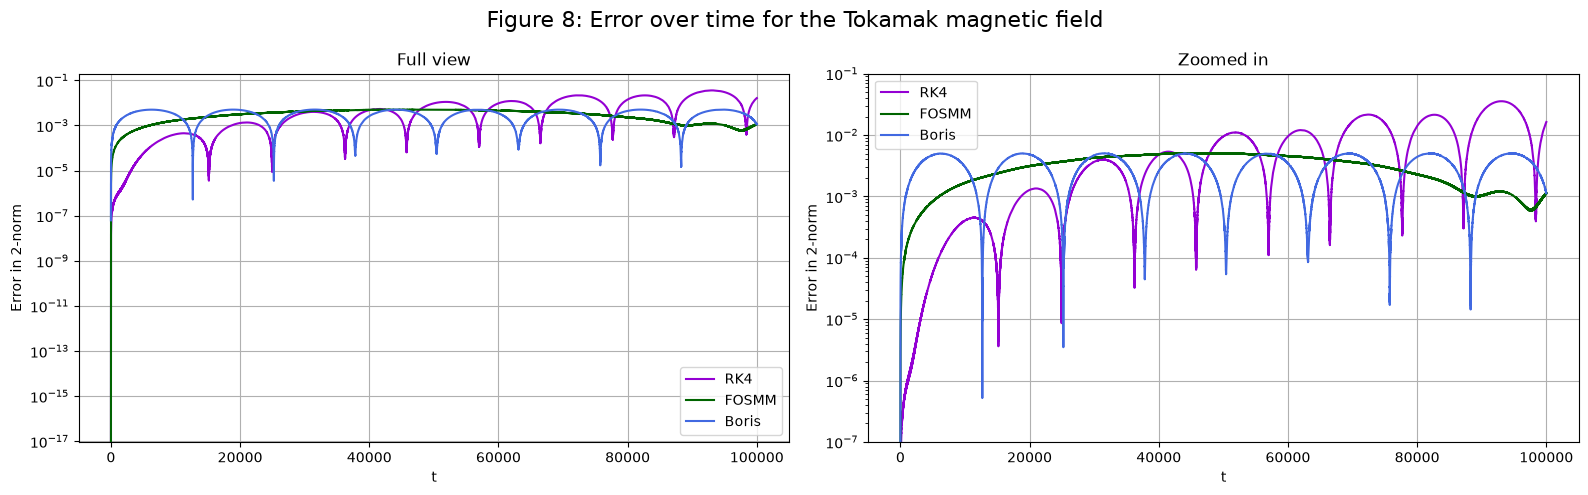

In [129]:
#computing error for tokamak field using all three models

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax in axes:
    ax.semilogy(t_A, err_RK4_tok, color='darkviolet', label='RK4')
    ax.semilogy(np.linspace(0, T_A, len(err_FOSMM_tok)), err_FOSMM_tok, color='darkgreen', label='FOSMM')
    ax.semilogy(t_A_boris, err_boris_tok, color='royalblue', label='Boris')
    ax.set_xlabel('t')
    ax.set_ylabel('Error in 2-norm')
    ax.legend()
    ax.grid(True)

axes[0].set_title('Full view')
axes[1].set_title('Zoomed in')
axes[1].set_ylim(1e-7, 1e-1) #adjusting limits

fig.suptitle('Figure 8: Error over time for the Tokamak magnetic field', fontsize=16)
plt.tight_layout()
plt.show()

In the plot, in figure 8, we see that the RK4 still reaches larger error-values than the other two methods. However the error for FOSMM appears to have lost some of its bumpy-shape. For this model we do not observe the same heavy oscillations as for the 2D model, but we can still observe the phase effects for boris method, and now also a similar effect for RK4. Perhaps the FOSMM also displays the same phenomenon but with a smaller phase change, such that the "period" is very long. This is hard to say without plotting for extremely long time periods.

### Investigating conservation of energy

#### Boris

In [130]:
#finding energy differences 
def energy_change_boris(x,v, initial_values, U):

    v_at_integers = 0.5* (v[:,:-1] + v[:, 1:]) #averaging to find v at integer steps
    energy_at_zero = energy(initial_values[0:3], initial_values[3:], U)
    x_array = x[:, :-1]
    energy_at_x_v = energy(x_array, v_at_integers, U)
    diff = np.abs(energy_at_x_v - energy_at_zero)

    return diff

dE_boris_2D = energy_change_boris(x_boris_2D, v_boris_2D, y0_2D, U_2D)
dE_boris_tok = energy_change_boris(x_boris_tok, v_boris_tok, y0_tok, U_tokamak)

t_eval_boris = t_A_boris[:-1]

#### RK4

In [131]:
#change in energy for RK4

dE_RK4_2D = energy_change(x_RK4_2D.T, v_RK4_2D.T, U_2D)
dE_RK4_tok = energy_change(x_RK4_tok.T, v_RK4_tok.T, U_tokamak)

#### FOSMM

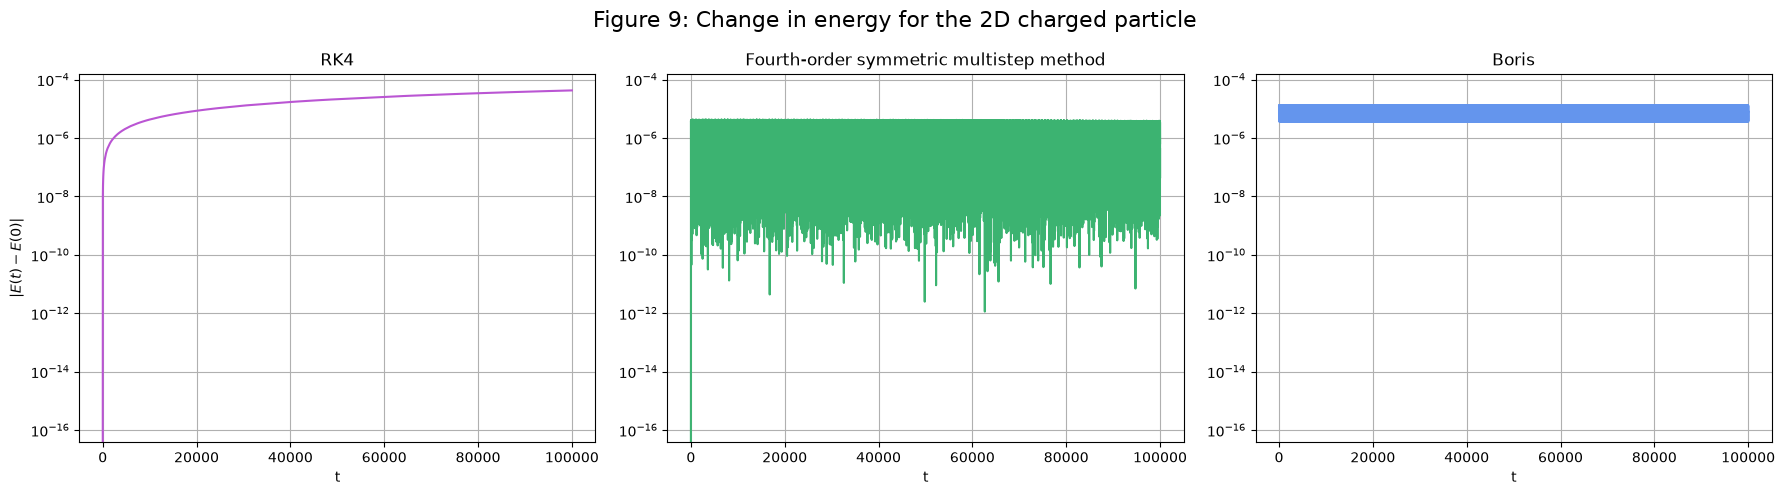

In [132]:
#plotting energy change for 2D particle
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

#RK4
axes[0].semilogy(t_A, dE_RK4_2D, color='mediumorchid')
axes[0].set_title('RK4')

#FOSMM
axes[1].semilogy(t_A, energy_change(x_FOSMM_2D, v_FOSMM_2D, U_2D), color='mediumseagreen')
axes[1].set_title('Fourth-order symmetric multistep method')

#Boris
axes[2].semilogy(t_eval_boris, dE_boris_2D, color='cornflowerblue')
axes[2].set_title('Boris')

for ax in axes:
    ax.set_xlabel('t')
    ax.grid(True)
    ax.tick_params(labelleft=True)
axes[0].set_ylabel(r'$|E(t) - E(0)|$')

fig.suptitle('Figure 9: Change in energy for the 2D charged particle', fontsize=16)
plt.tight_layout()
plt.show()

From the plots of change in energy in figure 9, we observe the following:

- RK4: The energy increases as expected for the RK4 method since it is a method that does not conserve the energy. The change in energy is zero at the initial condition and then increases to around $10^{-5}$. It remains larger than the change in energy for the other methods, and seems to keep on increasing slowly but steadily. 

- FOSMM: We observe that the upper bound for the energy difference stays constant and that there is a lot of fluctuations below this level. This resembles the plot in figure 5.1 in the second article. We observe no drift in energy, which is what we expect from the symmetric multistep method, since it is an energy-preserving method.
 
- Boris: In the Boris method the energy is preserved and only oscillates on a relatively small interval. 

In conclusion, the obtained results correspond to our expectations, as the energy is conserved for the Boris and multistep methods, while the energy for RK4 is not conserved.

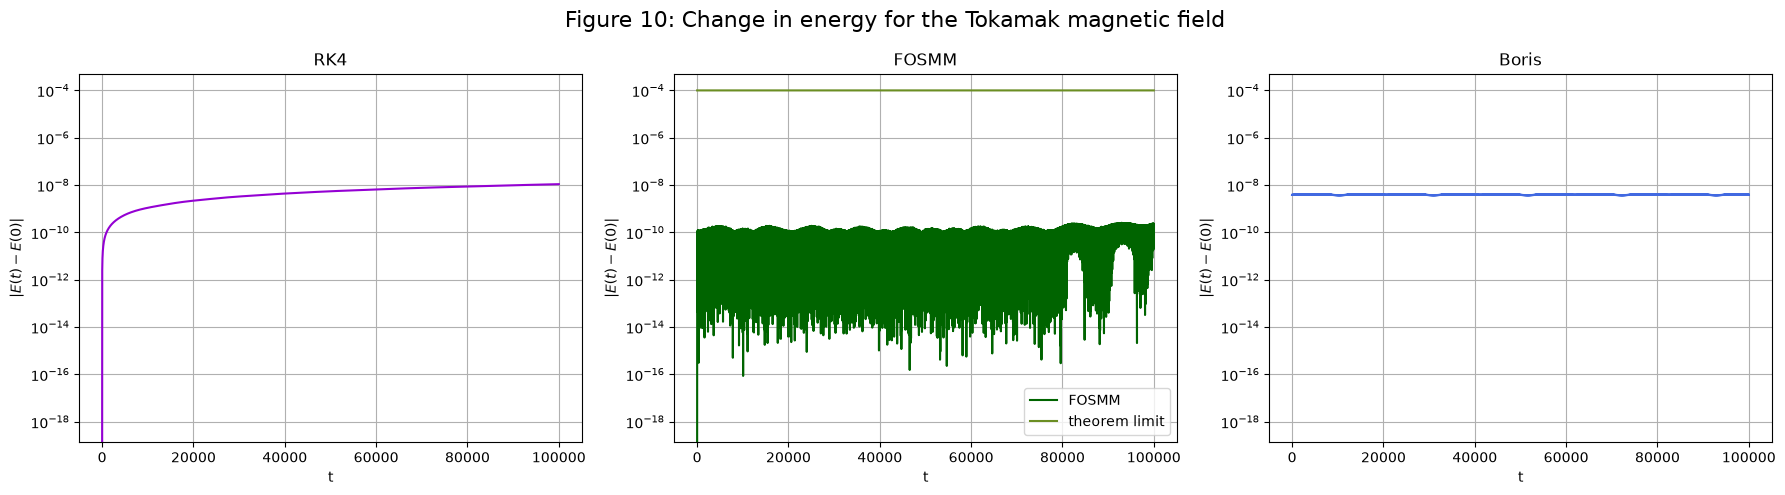

In [133]:
#plotting energy change for tokamak field
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

#RK4
axes[0].semilogy(t_A, dE_RK4_tok, color='darkviolet')
axes[0].set_title('RK4')

#FOSMM
axes[1].semilogy(t_A, energy_change(x_FOSMM_tok, v_FOSMM_tok, U_tokamak), color='darkgreen', label='FOSMM')
axes[1].semilogy(t_A, h_A**4*np.ones(len(t_A)), color='olivedrab', label='theorem limit')
axes[1].set_title('FOSMM')
axes[1].legend()

#Boris
axes[2].semilogy(t_eval_boris, dE_boris_tok, color='royalblue')
axes[2].set_title('Boris')

for ax in axes:
    ax.set_xlabel('t')
    ax.grid(True)
    ax.tick_params(labelleft=True)
    ax.set_ylabel(r'$|E(t) - E(0)|$')
axes[0].set_ylabel(r'$|E(t) - E(0)|$')

fig.suptitle('Figure 10: Change in energy for the Tokamak magnetic field', fontsize=16)
plt.tight_layout()
plt.show()

Figure 10 shows change in energy over time for the three methods applied to the Tokamak field model. For this model we observe similar behaviour from each method as what we saw in figure 9. However, here the changes in energy is even smaller.

Theorem 3.2 in article 2 states that the total energy for FOSMM should be conserved up to $O(h^p)$ over times $O(h^{-p-2})$. Our time interval is $[0, 10^5]$ and thus within the bound of $C h^{-4-2}$. As we can observe from the light-green line, our change in energy is $O(h^p)$, so the property of the theorem is satisfied by our numerical solution. 

The change in energy using the RK4 method is increasing, as before, and the energy is conserved for the Boris method.

 

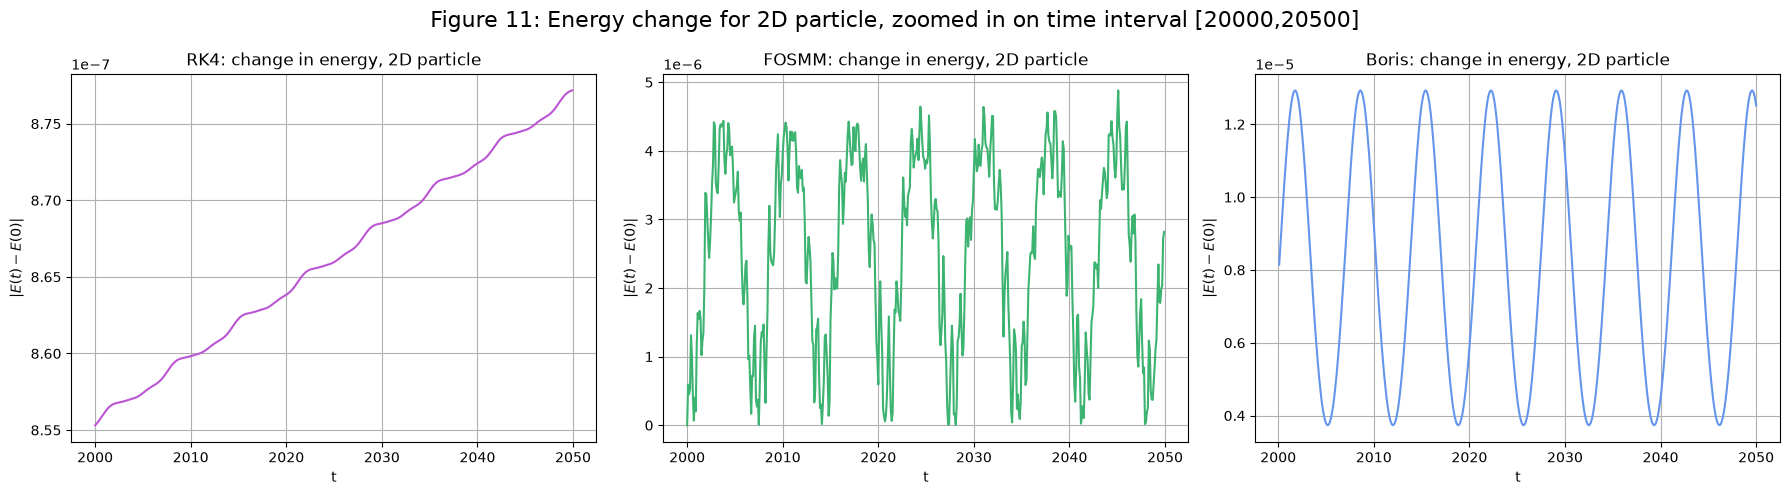

In [140]:
#zooming in on smaller time interval
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

#RK4
axes[0].plot(t_A[20000:20500], dE_RK4_2D[20000:20500], color="mediumorchid")
axes[0].set_title("RK4: change in energy, 2D particle")
axes[0].set_xlabel("t")
axes[0].set_ylabel(r"$|E(t) - E(0)|$")

#FOSMM
axes[1].plot(t_A[20000:20500], energy_change(x_FOSMM_2D[:,20000:20500], v_FOSMM_2D[:,20000:20500], U_2D), color="mediumseagreen")
axes[1].set_title("FOSMM: change in energy, 2D particle")
axes[1].set_xlabel("t")
axes[1].set_ylabel(r"$|E(t) - E(0)|$")

#Boris
axes[2].plot(t_A_boris[20000:20500], dE_boris_2D[20000:20500], color="cornflowerblue")
axes[2].set_title("Boris: change in energy, 2D particle")
axes[2].set_xlabel("t")
axes[2].set_ylabel(r"$|E(t) - E(0)|$")

for ax in axes:
    ax.grid(True)

fig.suptitle("Figure 11: Energy change for 2D particle, zoomed in on time interval [20000,20500]", fontsize=16)
plt.tight_layout()
plt.show()

In figure 11, we see a zoomed in version of the change in energy for the 2D charged particle. The fluctuations in the symmetric multistep method and Boris are relatively small, respectively on a scale $10^{-6}$ and $10^{-5}$. As we can see, the methods that conserve physical properties have energy changes that seem to fluctuate around a constant value. The change in energy for the RK4 method, however, increases with time.

## Task B

### Order verification

In [166]:
#parameters
T_B = [1e4, 1e3, 1e2, 10]
h_B = 0.1/2**np.arange(3) #decreasing values of step size

#### Boris method

In [ ]:
def error_boris_decrease(T):
    """
    Computing global error at final time step for decreasing T and h.
    """
    errors_2d = []
    errors_tok = []
    time_list_2d = []
    time_list_tok = []

    for h in h_B:
        N = int(T/h)

        t_span = (0, T)
        t_eval = np.arange(1, N+1)*h

        x_boris_2D_h, _, time_2d = boris_method(ODEs, x0_2D, v0_2D, h, U_2D, grad_U_2D, B_2D, True, N)

        sol_2D = solve_ivp(ODEs, t_span, y0_2D,
                args=(B_2D, grad_U_2D),
                method="DOP853", rtol=1e-12, atol=1e-14, t_eval=t_eval)

        x_boris_tok_h, _, time_tok = boris_method(ODEs, x0_tokamak, v0_tokamak, h, U_tokamak, grad_U_tokamak, B_tokamak, True, N)

        time_list_2d.append(time_2d)
        time_list_tok.append(time_tok)

        sol_tok = solve_ivp(ODEs, t_span, y0_tok,
                args=(B_tokamak, grad_U_tokamak),
                method="DOP853", rtol=1e-12, atol=1e-14, t_eval=t_eval)

        #compare global error in last step
        norm_2D = np.linalg.norm(x_boris_2D_h[:,-1] - sol_2D.y[:3,-1], ord = 2)
        norm_tok = np.linalg.norm(x_boris_tok_h[:,-1] - sol_tok.y[:3,-1], ord = 2)

        errors_2d.append(norm_2D)
        errors_tok.append(norm_tok)

    return errors_2d, errors_tok, time_list_2d, time_list_tok

In [ ]:
#computing errors and times for each end time in T_B
results_boris = [error_boris_decrease(T) for T in T_B]

err_boris_2D_B   = [r[0] for r in results_boris]
err_boris_tok_B  = [r[1] for r in results_boris]
time_boris_2D_B  = [r[2] for r in results_boris]
time_boris_tok_B = [r[3] for r in results_boris]

#### RK4 method

In [ ]:
def error_RK4_decrease(T):
    """
    Computing global error at final time step for decreasing T and h.
    """

    N_h = (T / h_B).astype(int)

    #reference solutions
    sol_2D = solve_ivp(
        ODEs, (0, T), y0_2D,
        args=(B_2D, grad_U_2D),
        method='DOP853',
        rtol=1e-12,
        atol=1e-14,
        t_eval=[T] #only evaluating at end time T
    )

    sol_tokamak = solve_ivp(
        ODEs, (0, T), y0_tok,
        args=(B_tokamak, grad_U_tokamak),
        method='DOP853',
        rtol=1e-12,
        atol=1e-14,
        t_eval=[T] #only evaluating at end time T
    )

    error_2D = []
    error_tokamak = []
    time_2D = []
    time_tokamak = []

    #RK4 for each step size
    for i in range(3):

        #2D particle
        y_n = y0_2D.copy()
        start = perf_counter() #measure time
        for j in range(N_h[i]):
            y_n = RK4_step(y_n, h_B[i], B_2D, grad_U_2D)
        end = perf_counter()
        time_2D.append(end - start)
        error_2D.append(np.linalg.norm(y_n[:3] - sol_2D.y[:3, -1]))

        #Tokamak field
        y_n = y0_tok.copy()
        start = perf_counter() #measure time
        for j in range(N_h[i]):
            y_n = RK4_step(y_n, h_B[i], B_tokamak, grad_U_tokamak)
        end = perf_counter()
        time_tokamak.append(end - start)
        error_tokamak.append(np.linalg.norm(y_n[:3] - sol_tokamak.y[:3, -1]))

    return error_2D, error_tokamak, time_2D, time_tokamak

In [145]:
results_RK4 = [error_RK4_decrease(T) for T in T_B]

err_RK4_2D_B   = [r[0] for r in results_RK4]
err_RK4_tok_B  = [r[1] for r in results_RK4]
time_RK4_2D_B  = [r[2] for r in results_RK4]
time_RK4_tok_B = [r[3] for r in results_RK4]

#### FOSMM

In [146]:
err_FOSMM_2D_B = []
err_FOSMM_tok_B = []
time_FOSMM_2D_B = []
time_FOSMM_tok_B = []

#find error and time for all step sizes and all T values
for T in T_B:
    e_2D = []
    e_tok = []
    t_2D = []
    t_tok = []
    for h in h_B:
        N = int(T/h) + 1
        t_eval = np.linspace(0, T, N)
        x_2D, _, time_2D = FOSMM(alpha, h, A_2D, grad_U_2D, B_2D, beta, T, y0_FOSMM_2D)
        x_tok, _, time_tok = FOSMM(alpha, h, A_tokamak, grad_U_tokamak, B_tokamak, beta, T, y0_FOSMM_tok)

        ref_2D = solve_ivp(ODEs, (0, T), y0_2D, args=(B_2D, grad_U_2D), method="DOP853", rtol=1e-12, atol=1e-14, t_eval=t_eval)
        ref_tok = solve_ivp(ODEs, (0, T), y0_tok, args=(B_tokamak, grad_U_tokamak), method="DOP853", rtol=1e-12, atol=1e-14, t_eval=t_eval)

        t_2D.append(time_2D)
        t_tok.append(time_tok)

        e_2D.append(np.linalg.norm(x_2D[:,-1] - ref_2D.y[:3,-1], ord=2))
        e_tok.append(np.linalg.norm(x_tok[:,-1] - ref_tok.y[:3,-1], ord=2))

    err_FOSMM_2D_B.append(e_2D)
    err_FOSMM_tok_B.append(e_tok)
    time_FOSMM_2D_B.append(t_2D)
    time_FOSMM_tok_B.append(t_tok)

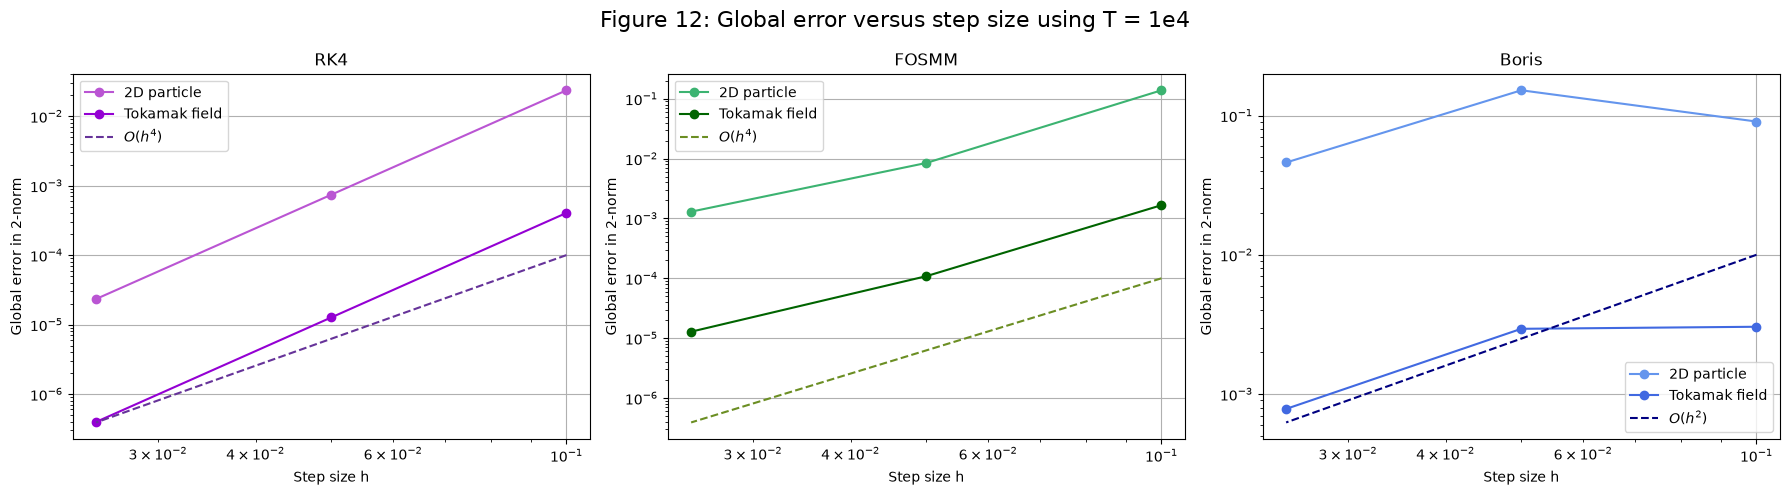

In [147]:
#Plotting global error vs step size h, T = 1e4
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

#RK4
axes[0].loglog(h_B, err_RK4_2D_B[0], 'o-', label='2D particle', color='mediumorchid')
axes[0].loglog(h_B, err_RK4_tok_B[0], 'o-', label='Tokamak field', color='darkviolet')
axes[0].loglog(h_B, h_B**4, '--', label=r'$O(h^4)$', color='rebeccapurple')
axes[0].set_title('RK4')

#FOSMM
axes[1].loglog(h_B, err_FOSMM_2D_B[0], 'o-', label='2D particle', color='mediumseagreen')
axes[1].loglog(h_B, err_FOSMM_tok_B[0], 'o-', label='Tokamak field', color='darkgreen')
axes[1].loglog(h_B, h_B**4, '--', label=r'$O(h^4)$', color='olivedrab')
axes[1].set_title('FOSMM')

#Boris
axes[2].loglog(h_B, err_boris_2D_B[0], 'o-', label='2D particle', color='cornflowerblue')
axes[2].loglog(h_B, err_boris_tok_B[0], 'o-', label='Tokamak field', color='royalblue')
axes[2].loglog(h_B, h_B**2, '--', label=r'$O(h^2)$', color='navy')
axes[2].set_title('Boris')

for ax in axes:
    ax.set_xlabel('Step size h')
    ax.set_ylabel('Global error in 2-norm')
    ax.grid(True)
    ax.legend()

fig.suptitle('Figure 12: Global error versus step size using T = 1e4', fontsize=16)
plt.tight_layout()
plt.show()

In this task we plot the global error of each method in the final time step, for decreasing values of $h$, in order to verify the expected order of convergence. A method of order $p$ should have a global error that is $O(h^p)$. 

Figure 12 displays such a plot. For RK4, we can see that the global error for this interval of $T$ and $h$ follows a steeper slope than the reference line of $h^4$ which has a slope of 4 when plotted with logarithmic axes. Since the lines are steeper, for some value $h_0$, we will find the error to follow a function that is smaller than or equal in value to $C h^4$ for $h <= h_0$. Thus satisfying the condition of the error being $O(h^4)$.

The error plots for the Boris method and FOSMM, however, do not behave as we would expect. These methods are of orders 2 and 4 respectively, and should therefore be at least parallel to the reference line of respectively $h^2, h^4$. Perhaps this could be explained by long-term accumulation of numerical error. We imagine this can be caused by limitations such as floating-point rounding errors, where the conditions for stability might not be satisfied when this occurs. We assume this error factor should decrease if the number of time steps is lower, and we therefore investigate this further by reducing the end times.



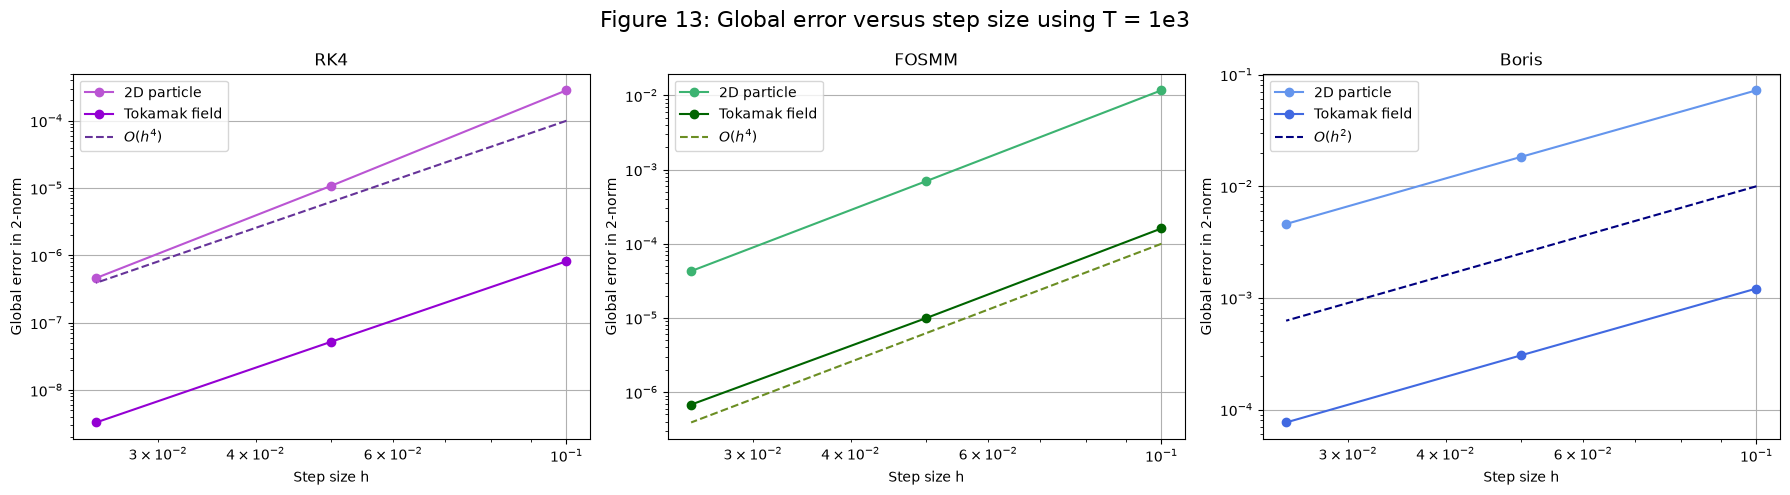

In [148]:
#Plotting global error vs step size, T = 1e3
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

#RK4
axes[0].loglog(h_B, err_RK4_2D_B[1], 'o-', label='2D particle', color='mediumorchid')
axes[0].loglog(h_B, err_RK4_tok_B[1], 'o-', label='Tokamak field', color='darkviolet')
axes[0].loglog(h_B, h_B**4, '--', label=r'$O(h^4)$', color='rebeccapurple')
axes[0].set_title('RK4')

#FOSMM
axes[1].loglog(h_B, err_FOSMM_2D_B[1], 'o-', label='2D particle', color='mediumseagreen')
axes[1].loglog(h_B, err_FOSMM_tok_B[1], 'o-', label='Tokamak field', color='darkgreen')
axes[1].loglog(h_B, h_B**4, '--', label=r'$O(h^4)$', color='olivedrab')
axes[1].set_title('FOSMM')

#Boris
axes[2].loglog(h_B, err_boris_2D_B[1], 'o-', label='2D particle', color='cornflowerblue')
axes[2].loglog(h_B, err_boris_tok_B[1], 'o-', label='Tokamak field', color='royalblue')
axes[2].loglog(h_B, h_B**2, '--', label=r'$O(h^2)$', color='navy')
axes[2].set_title('Boris')

for ax in axes:
    ax.set_xlabel('Step size h')
    ax.set_ylabel('Global error in 2-norm')
    ax.grid(True)
    ax.legend()

fig.suptitle('Figure 13: Global error versus step size using T = 1e3', fontsize=16)
plt.tight_layout()
plt.show()

In figure 13 we have repeated the exercise for $T = 10^3$, and we already see a large improvement. Now all the methods show convergence in their respective order. 

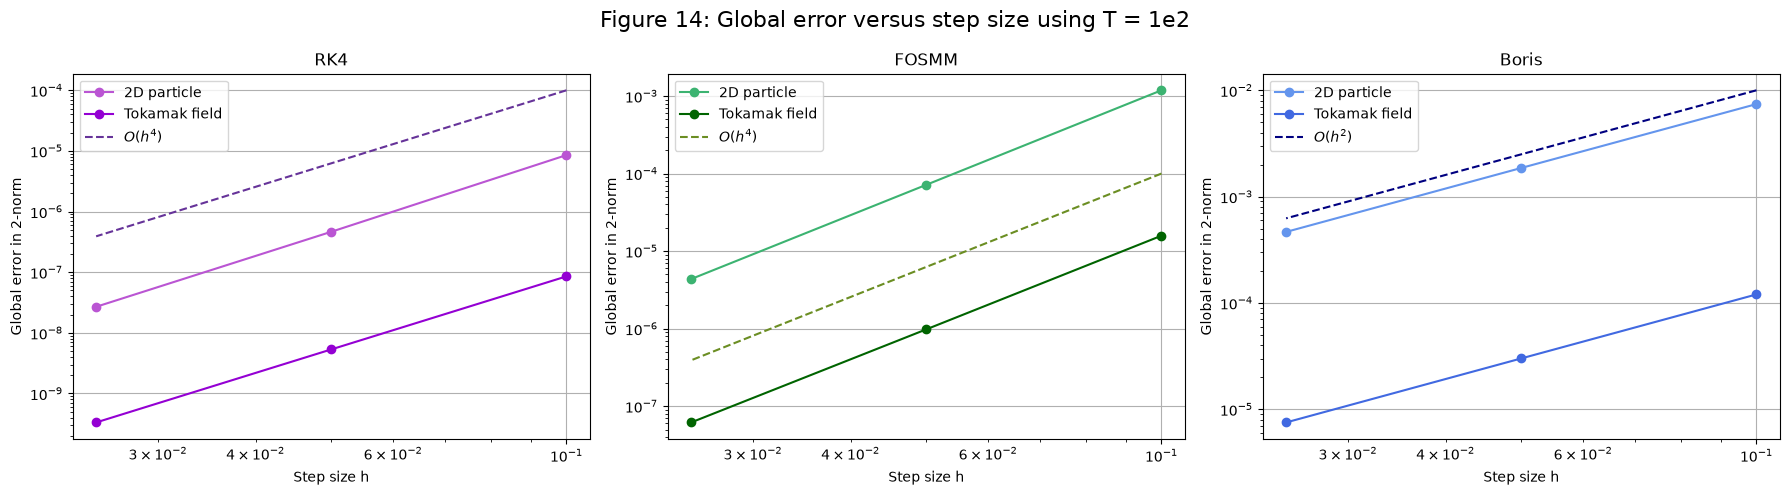

In [149]:
#Plotting global error vs step size h, T = 1e2
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

#RK4
axes[0].loglog(h_B, err_RK4_2D_B[2], 'o-', label='2D particle', color='mediumorchid')
axes[0].loglog(h_B, err_RK4_tok_B[2], 'o-', label='Tokamak field', color='darkviolet')
axes[0].loglog(h_B, h_B**4, '--', label=r'$O(h^4)$', color='rebeccapurple')
axes[0].set_title('RK4')

#FOSMM
axes[1].loglog(h_B, err_FOSMM_2D_B[2], 'o-', label='2D particle', color='mediumseagreen')
axes[1].loglog(h_B, err_FOSMM_tok_B[2], 'o-', label='Tokamak field', color='darkgreen')
axes[1].loglog(h_B, h_B**4, '--', label=r'$O(h^4)$', color='olivedrab')
axes[1].set_title('FOSMM')

#Boris
axes[2].loglog(h_B, err_boris_2D_B[2], 'o-', label='2D particle', color='cornflowerblue')
axes[2].loglog(h_B, err_boris_tok_B[2], 'o-', label='Tokamak field', color='royalblue')
axes[2].loglog(h_B, h_B**2, '--', label=r'$O(h^2)$', color='navy')
axes[2].set_title('Boris')

for ax in axes:
    ax.set_xlabel('Step size h')
    ax.set_ylabel('Global error in 2-norm')
    ax.grid(True)
    ax.legend()

fig.suptitle('Figure 14: Global error versus step size using T = 1e2', fontsize=16)
plt.tight_layout()
plt.show()

Figure 14 shows a plot of the same experiment for $T=10^2$, again showing satisfactory order of convergence. 

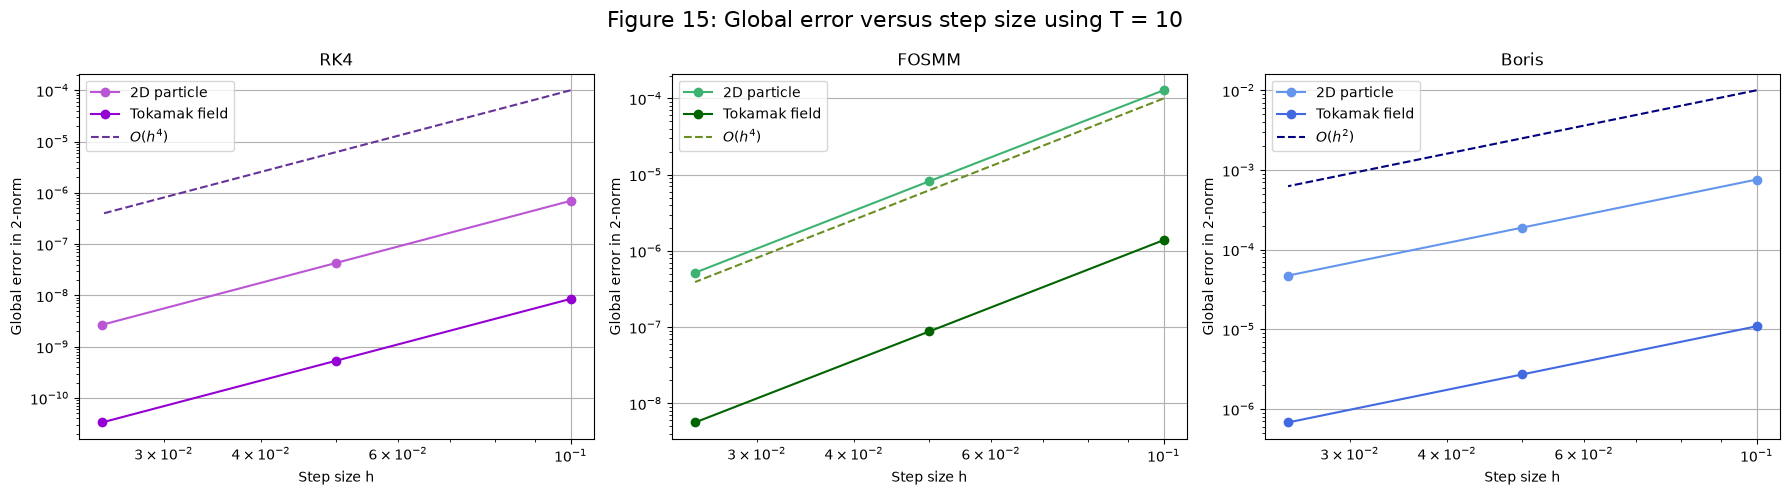

In [150]:
#plotting global error vs step size, T = 10
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

#RK4
axes[0].loglog(h_B, err_RK4_2D_B[3], 'o-', label='2D particle', color='mediumorchid')
axes[0].loglog(h_B, err_RK4_tok_B[3], 'o-', label='Tokamak field', color='darkviolet')
axes[0].loglog(h_B, h_B**4, '--', label=r'$O(h^4)$', color='rebeccapurple')
axes[0].set_title('RK4')

#FOSMM
axes[1].loglog(h_B, err_FOSMM_2D_B[3], 'o-', label='2D particle', color='mediumseagreen')
axes[1].loglog(h_B, err_FOSMM_tok_B[3], 'o-', label='Tokamak field', color='darkgreen')
axes[1].loglog(h_B, h_B**4, '--', label=r'$O(h^4)$', color='olivedrab')
axes[1].set_title('FOSMM')

#Boris
axes[2].loglog(h_B, err_boris_2D_B[3], 'o-', label='2D particle', color='cornflowerblue')
axes[2].loglog(h_B, err_boris_tok_B[3], 'o-', label='Tokamak field', color='royalblue')
axes[2].loglog(h_B, h_B**2, '--', label=r'$O(h^2)$', color='navy')
axes[2].set_title('Boris')

for ax in axes:
    ax.set_xlabel('Step size h')
    ax.set_ylabel('Global error in 2-norm')
    ax.grid(True)
    ax.legend()

fig.suptitle('Figure 15: Global error versus step size using T = 10', fontsize=16)
plt.tight_layout()
plt.show()

Figure 15 shows a plot of the same experiment for $T=10$, once again showing satisfactory order of convergence. Our assumption appears to be correct.

### Work precision diagrams

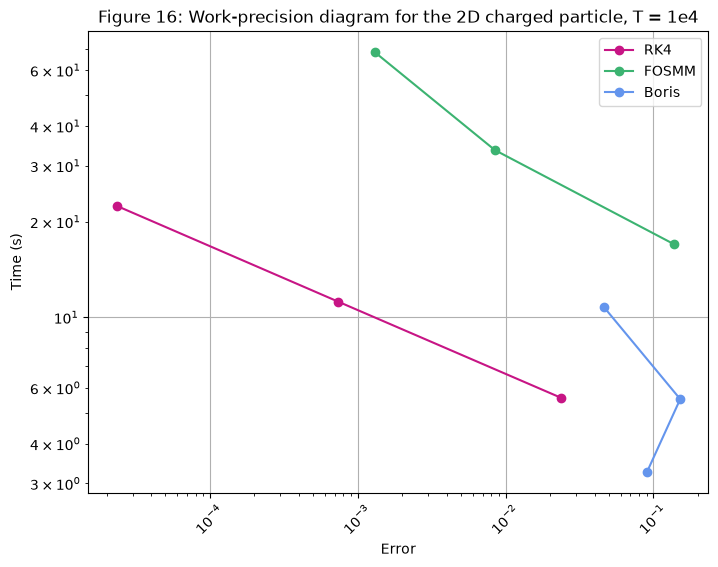

In [151]:
#work-precision diagram for the 2D-particle, T = 1e-4
plt.figure(figsize=(8, 6))

plt.loglog(err_RK4_2D_B[0], time_RK4_2D_B[0], 'o-', color='mediumvioletred', label='RK4')
plt.loglog(err_FOSMM_2D_B[0], time_FOSMM_2D_B[0], 'o-', color='mediumseagreen', label='FOSMM')
plt.loglog(err_boris_2D_B[0], time_boris_2D_B[0], 'o-', color='cornflowerblue', label='Boris')

plt.xlabel('Error')
plt.ylabel('Time (s)')
plt.title('Figure 16: Work-precision diagram for the 2D charged particle, T = 1e4')
plt.tick_params(axis='x', which='both', labelrotation=45)
plt.legend()
plt.grid(True)
plt.show()

We now plot the global error along the x-axis, and the computational time of the method for the given $T$ and values $h_i, i = 0,1,2$ along the y-axis.
We would expect that higher accuracy requires longer computational time, for a given method.

In figure 16, we have plotted the work-precision diagram for all methods applied to the 2D particle model. Our expectations are fulfilled for the RK4 method and FOSMM, but not quite for the Boris method. For the Boris method, the error is in fact larger for $h_1$ than for $h_0$. We therefore repeat again for lower values of $T$, as in the previous experiment.

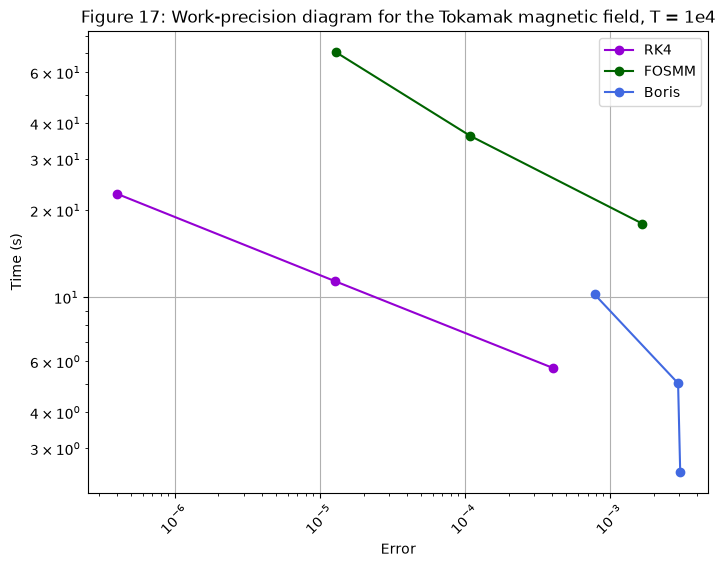

In [152]:
#work-precision diagram for the tokamak field, T = 1e-4
plt.figure(figsize=(8, 6))

plt.loglog(err_RK4_tok_B[0], time_RK4_tok_B[0], 'o-', color='darkviolet', label='RK4')
plt.loglog(err_FOSMM_tok_B[0], time_FOSMM_tok_B[0], 'o-', color='darkgreen', label='FOSMM')
plt.loglog(err_boris_tok_B[0], time_boris_tok_B[0], 'o-', color='royalblue', label='Boris')

plt.xlabel('Error')
plt.ylabel('Time (s)')
plt.title('Figure 17: Work-precision diagram for the Tokamak magnetic field, T = 1e4')
plt.tick_params(axis='x', which='both', labelrotation=45)
plt.legend()
plt.grid(True)
plt.show()

Figure 17 shows the same work-precision diagram, but this time on the Tokamak field model. We see a slight improvement for the Boris method, as $h_1$ no longer yields a larger error than $h_0$.

We investigate further to see if we can improve more, especially for the 2D model. Perhaps we can attain a similar behaviour as the other two methods?

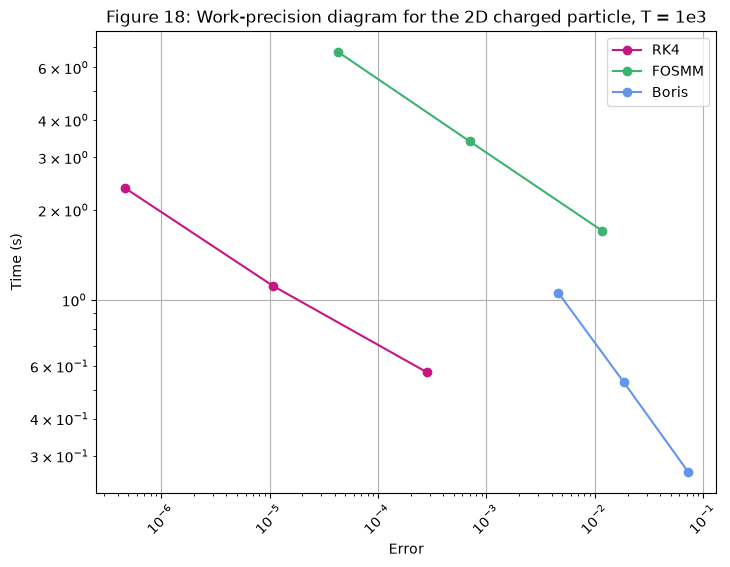

In [153]:
#work-precision diagram from the 2D-particle, T = 1e-3
plt.figure(figsize=(8, 6))

plt.loglog(err_RK4_2D_B[1], time_RK4_2D_B[1], 'o-', color='mediumvioletred', label='RK4')
plt.loglog(err_FOSMM_2D_B[1], time_FOSMM_2D_B[1], 'o-', color='mediumseagreen', label='FOSMM')
plt.loglog(err_boris_2D_B[1], time_boris_2D_B[1], 'o-', color='cornflowerblue', label='Boris')

plt.xlabel('Error')
plt.ylabel('Time (s)')
plt.title('Figure 18: Work-precision diagram for the 2D charged particle, T = 1e3')
plt.tick_params(axis='x', which='both', labelrotation=45)
plt.legend()
plt.grid(True)
plt.show()

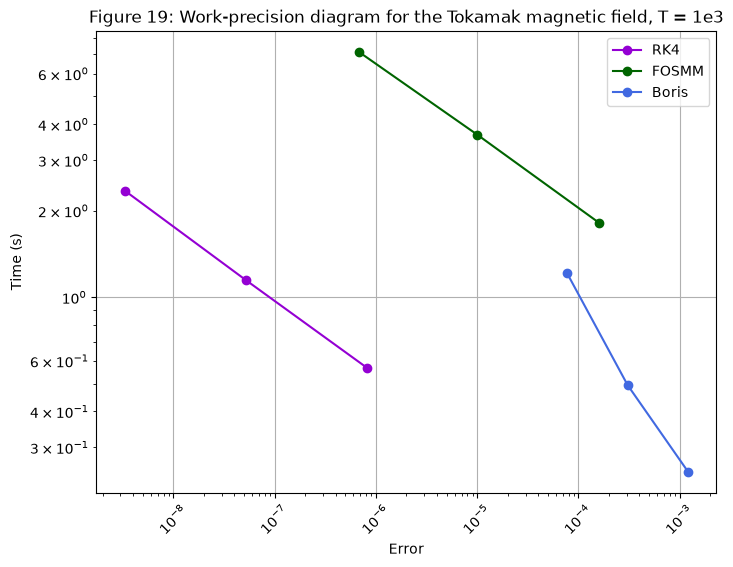

In [154]:
#work-precision diagram for the tokamak, T = 1e-3
plt.figure(figsize=(8, 6))

plt.loglog(err_RK4_tok_B[1], time_RK4_tok_B[1], 'o-', color='darkviolet', label='RK4')
plt.loglog(err_FOSMM_tok_B[1], time_FOSMM_tok_B[1], 'o-', color='darkgreen', label='FOSMM')
plt.loglog(err_boris_tok_B[1], time_boris_tok_B[1], 'o-', color='royalblue', label='Boris')

plt.xlabel('Error')
plt.ylabel('Time (s)')
plt.title('Figure 19: Work-precision diagram for the Tokamak magnetic field, T = 1e3')
plt.tick_params(axis='x', which='both', labelrotation=45)
plt.legend()
plt.grid(True)
plt.show()

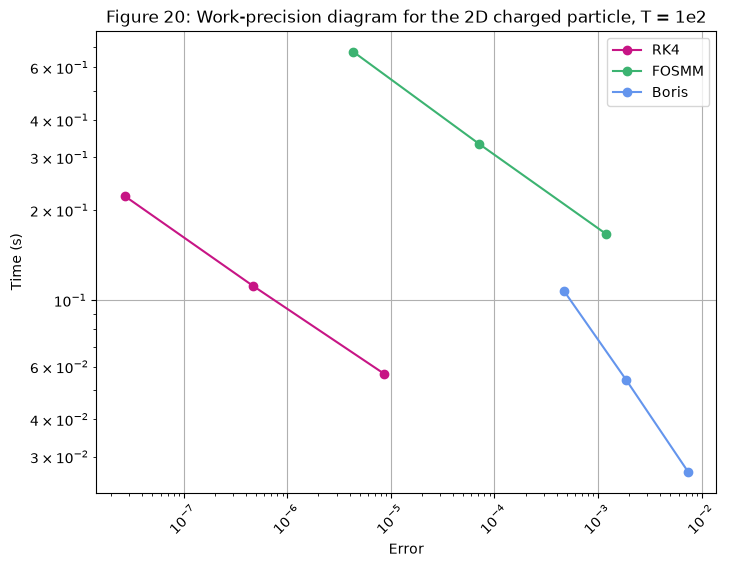

In [155]:
#work-precision diagram for the 2D-particle, T = 1e-2
plt.figure(figsize=(8, 6))

plt.loglog(err_RK4_2D_B[2], time_RK4_2D_B[2], 'o-', color='mediumvioletred', label='RK4')
plt.loglog(err_FOSMM_2D_B[2], time_FOSMM_2D_B[2], 'o-', color='mediumseagreen', label='FOSMM')
plt.loglog(err_boris_2D_B[2], time_boris_2D_B[2], 'o-', color='cornflowerblue', label='Boris')

plt.xlabel('Error')
plt.ylabel('Time (s)')
plt.title('Figure 20: Work-precision diagram for the 2D charged particle, T = 1e2')
plt.tick_params(axis='x', which='both', labelrotation=45)
plt.legend()
plt.grid(True)
plt.show()

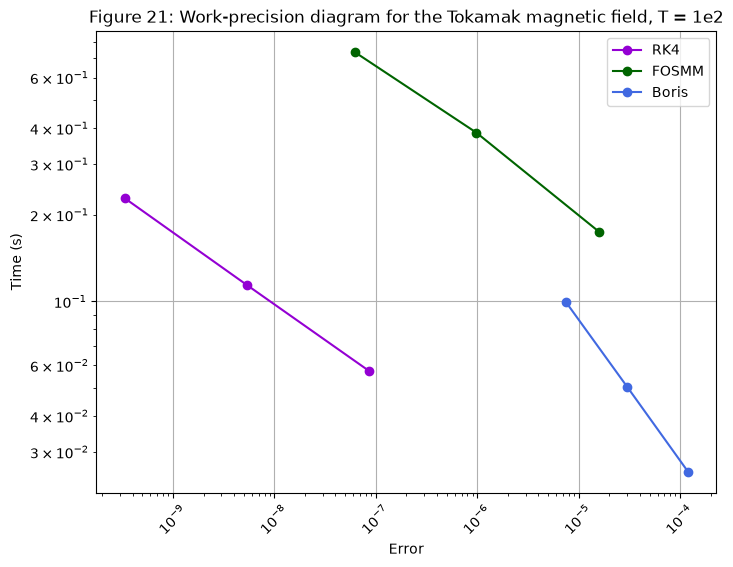

In [156]:
#work-precision diagram for tokamak field, T = 1e-2
plt.figure(figsize=(8, 6))

plt.loglog(err_RK4_tok_B[2], time_RK4_tok_B[2], 'o-', color='darkviolet', label='RK4')
plt.loglog(err_FOSMM_tok_B[2], time_FOSMM_tok_B[2], 'o-', color='darkgreen', label='FOSMM')
plt.loglog(err_boris_tok_B[2], time_boris_tok_B[2], 'o-', color='royalblue', label='Boris')

plt.xlabel('Error')
plt.ylabel('Time (s)')
plt.title('Figure 21: Work-precision diagram for the Tokamak magnetic field, T = 1e2')
plt.tick_params(axis='x', which='both', labelrotation=45)
plt.legend()
plt.grid(True)
plt.show()

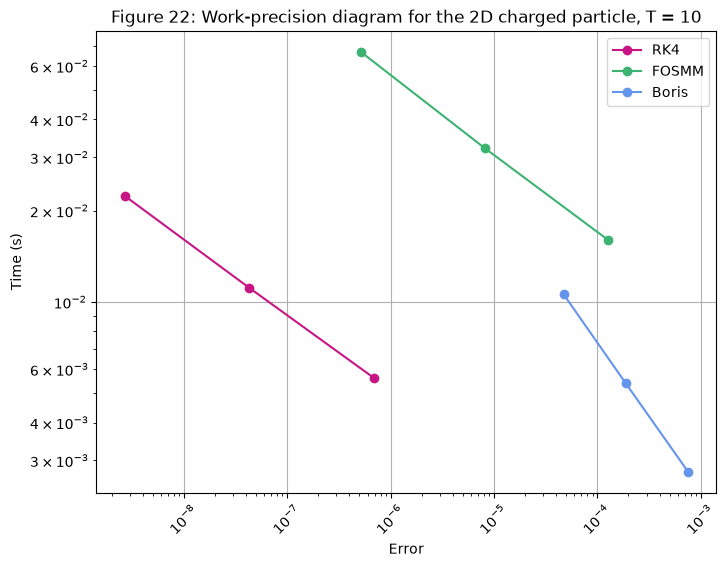

In [157]:
#work-precision diagram for the 2D-particle, T = 10
plt.figure(figsize=(8, 6))

plt.loglog(err_RK4_2D_B[3], time_RK4_2D_B[3], 'o-', color='mediumvioletred', label='RK4')
plt.loglog(err_FOSMM_2D_B[3], time_FOSMM_2D_B[3], 'o-', color='mediumseagreen', label='FOSMM')
plt.loglog(err_boris_2D_B[3], time_boris_2D_B[3], 'o-', color='cornflowerblue', label='Boris')

plt.xlabel('Error')
plt.ylabel('Time (s)')
plt.title('Figure 22: Work-precision diagram for the 2D charged particle, T = 10')
plt.tick_params(axis='x', which='both', labelrotation=45)
plt.legend()
plt.grid(True)
plt.show()

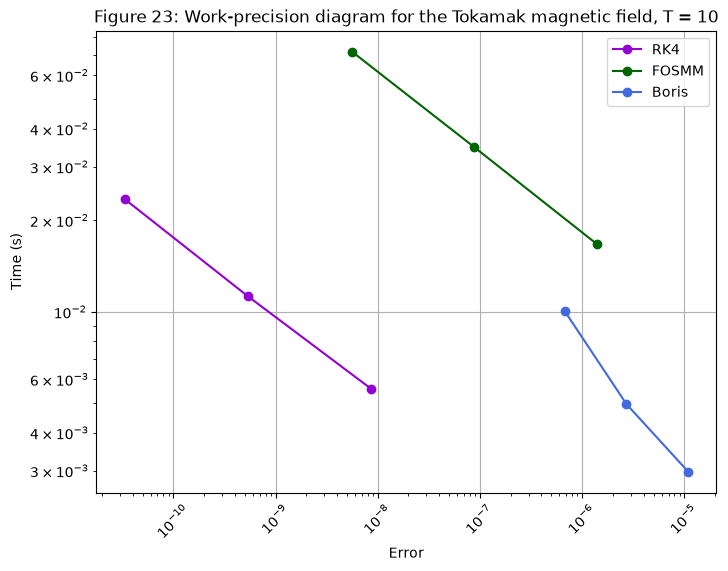

In [158]:
#work-precision diagram for the tokamak field, T = 10
plt.figure(figsize=(8, 6))

plt.loglog(err_RK4_tok_B[3], time_RK4_tok_B[3], 'o-', color='darkviolet', label='RK4')
plt.loglog(err_FOSMM_tok_B[3], time_FOSMM_tok_B[3], 'o-', color='darkgreen', label='FOSMM')
plt.loglog(err_boris_tok_B[3], time_boris_tok_B[3], 'o-', color='royalblue', label='Boris')

plt.xlabel('Error')
plt.ylabel('Time (s)')
plt.title('Figure 23: Work-precision diagram for the Tokamak magnetic field, T = 10')
plt.tick_params(axis='x', which='both', labelrotation=45)
plt.legend()
plt.grid(True)
plt.show()

Figure 18 through 23 show the work-precision diagrams for all three methods on both models, for decreasing $T$. For lower values of $T$, our expectation of higher computational time corresponding to higher accuracy, is fulfilled. 

In the work-precision diagrams above, we observe that the RK4 method in fact has the best precision for the least amount of time spent. FOSMM is the slowest in general, particularily for the smallest $h$-value. The Boris method is generally quicker, but has a larger error. 

In other words, the RK4 method does well at finding accurate positions for these particular initial value problems, at a small computational cost. However, as previously seen, the other methods preserve physical properties better, though at a cost of lower positional accuracy compared to the required computational time.


## Task C

For the exploratory task we have chosen to investigate the breakdown of the RK4 method by comparing it with the Boris method, for a new set of initial conditions for the Tokamak field model, given in article 3. This gives us the opportunity to explore a case when using the RK4 method is no longer advantageous.

Figure 6 in article 3 utilizes two sets of initial conditions, that lead to different trajectories for the Tokamak field model.

#### Solving the system with RK4

In [159]:
#solving with RK4 using initial conditions from article 3
#params
T_C = 2e5
h_C = np.pi/10
n_steps_C = int(T_C/h_C)
time_C = np.linspace(0, T_C, n_steps_C + 1)


y_arr_tokamak_RK4_C_banana = np.zeros((n_steps_C + 1, 6))
y_arr_tokamak_RK4_C_transit = np.zeros((n_steps_C + 1, 6))

x0_tokamak_C = np.array([1.05,0,0])
v0_tokamak_C_banana = np.array([0,4.816e-4,-2.059e-3]) #for banana orbit
v0_tokamak_C_transit = np.array([0,2*4.816e-4,-2.059e-3]) #for transit orbit, v_y is doubled

#initial condiytions
y_arr_tokamak_RK4_C_banana[0] = np.concatenate((
    np.asarray(x0_tokamak_C), np.asarray(v0_tokamak_C_banana)))
y_arr_tokamak_RK4_C_transit[0] = np.concatenate((
    np.asarray(x0_tokamak_C), np.asarray(v0_tokamak_C_transit)))

y_n_RK4_banana = np.concatenate((x0_tokamak_C, v0_tokamak_C_banana))
y_n_RK4_transit = np.concatenate((x0_tokamak_C, v0_tokamak_C_transit))

for i in tqdm(range(n_steps_C)):
    y_n_RK4_banana = RK4_step(y_n_RK4_banana, h_C, B_tokamak, grad_U_tokamak)
    y_n_RK4_transit = RK4_step(y_n_RK4_transit, h_C, B_tokamak, grad_U_tokamak)

    y_arr_tokamak_RK4_C_banana[i+1] = np.asarray(y_n_RK4_banana)
    y_arr_tokamak_RK4_C_transit[i+1] = np.asarray(y_n_RK4_transit)

x_arr_tokamak_RK4_C_banana = y_arr_tokamak_RK4_C_banana[:, :3] #positions banana orbit
v_arr_tokamak_RK4_C_banana = y_arr_tokamak_RK4_C_banana[:, 3:] #velocities banana orbit

x_arr_tokamak_RK4_C_transit = y_arr_tokamak_RK4_C_transit[:, :3] #positions transit orbit
v_arr_tokamak_RK4_C_transit = y_arr_tokamak_RK4_C_transit[:, 3:] #velocity transit orbit

100%|██████████| 636619/636619 [01:13<00:00, 8710.21it/s]


In [ ]:
#R = sqrt(x^2 + y^2)
R_RK4_C_banana = np.sqrt(x_arr_tokamak_RK4_C_banana[:, 0]**2 + x_arr_tokamak_RK4_C_banana[:, 1]**2)
R_RK4_C_transit = np.sqrt(x_arr_tokamak_RK4_C_transit[:, 0]**2 + x_arr_tokamak_RK4_C_transit[:, 1]**2)

#z coordinates
x3_RK4_C_banana = x_arr_tokamak_RK4_C_banana[:, 2]
x3_RK4_C_transit = x_arr_tokamak_RK4_C_transit[:, 2]

In [161]:
#calculate relative energy error (for banana orbit)
E_n_tokamak_RK4_C = energy(x_arr_tokamak_RK4_C_banana.T, v_arr_tokamak_RK4_C_banana.T, U_tokamak)
E0_tokamak_RK4_C = E_n_tokamak_RK4_C[0]

error_energy_tokamak = (E_n_tokamak_RK4_C - E0_tokamak_RK4_C) / np.abs(E0_tokamak_RK4_C)

#### Solving the system with the Boris method

In [162]:
#solving with Boris using initial conditions from article 3

x_c_boris_banana, v_c_boris_banana, _ = boris_method(ODEs, x0_tokamak_C, v0_tokamak_C_banana, h_C, U_tokamak, grad_U_tokamak, B_tokamak, True, n_steps_C)

x_c_boris_transit, v_c_boris_transit, _ = boris_method(ODEs, x0_tokamak_C, v0_tokamak_C_transit, h_C, U_tokamak, grad_U_tokamak, B_tokamak, True, n_steps_C)


In [163]:
t_span_c_boris = (0,T_C)
t_eval_c_boris = np.arange(1, n_steps_C+1)*h_C

R_boris_C_banana = np.sqrt(x_c_boris_banana[0]**2 + x_c_boris_banana[1]**2)
R_boris_C_transit = np.sqrt(x_c_boris_transit[0]**2 + x_c_boris_transit[1]**2)

#energy
energy_tokamak_boris_C = energy(x_c_boris_banana,v_c_boris_banana,U_tokamak)
E0_tokamak_boris = energy_tokamak_boris_C[0] #at first position

error_energy_tokamak_boris = (energy_tokamak_boris_C - E0_tokamak_boris)/np.abs(E0_tokamak_boris)

#### Plotting and comparing the two methods

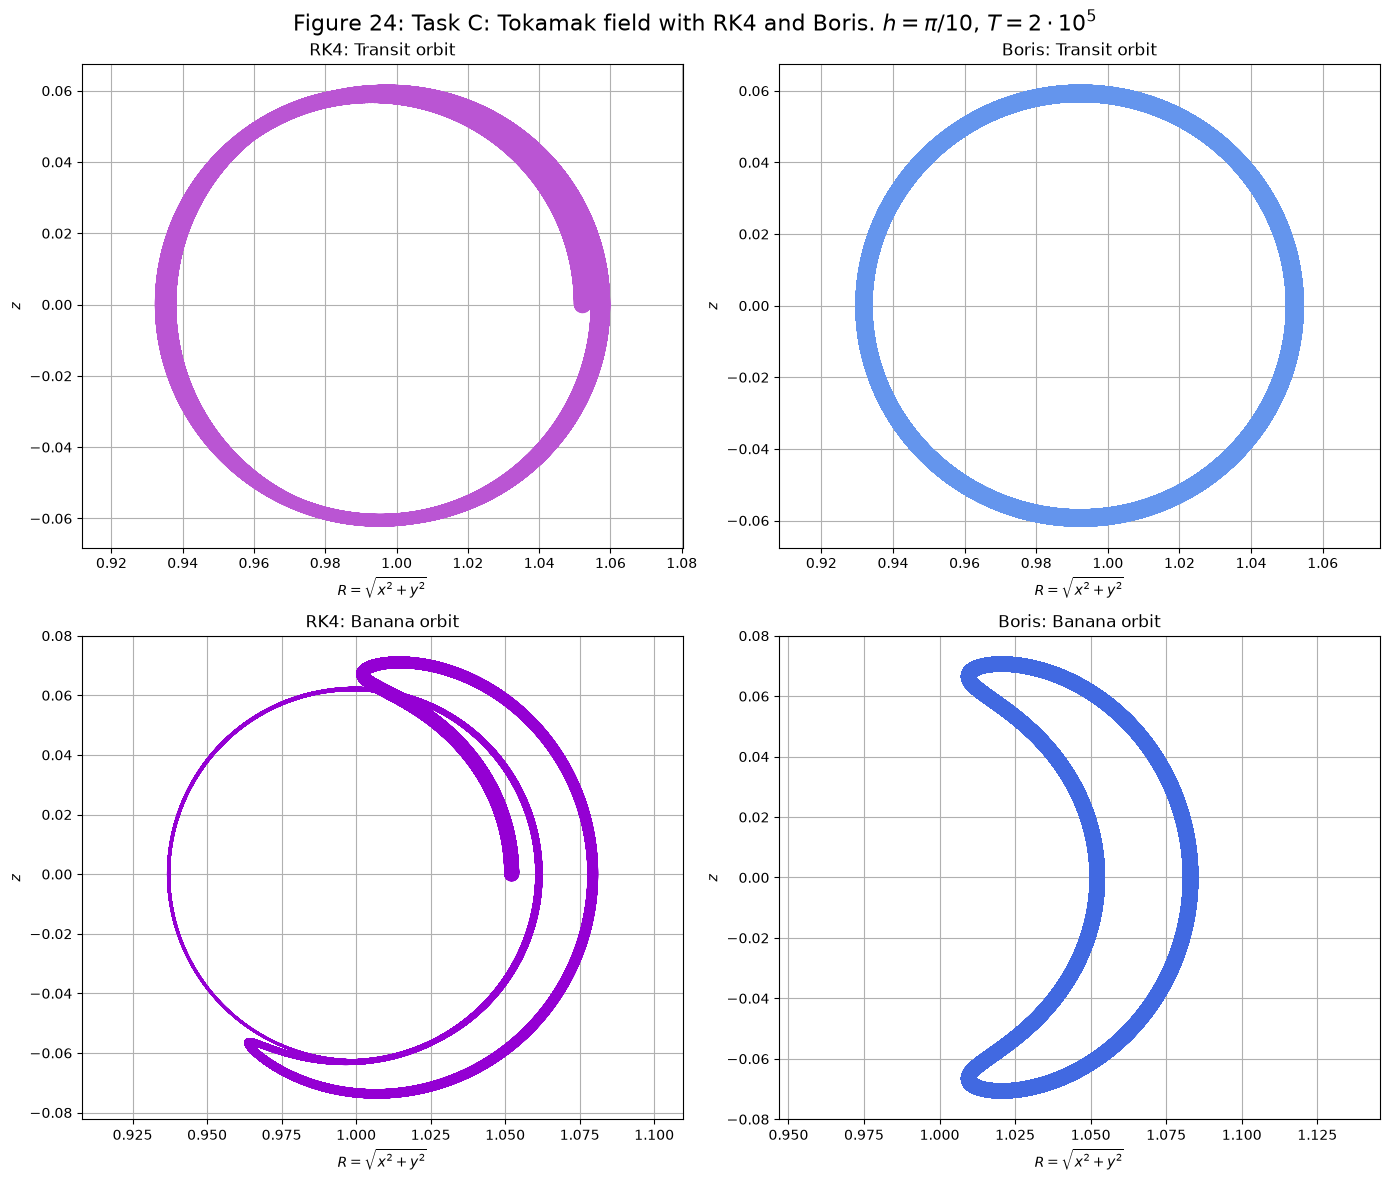

In [164]:
#plotting trajectories in R-z-plane for both initial conditions
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

#RK4, (R,z)-plane, Transit orbit
axes[0, 0].plot(R_RK4_C_transit, x_arr_tokamak_RK4_C_transit[:, 2], color="mediumorchid")
axes[0, 0].set_title("RK4: Transit orbit")

#Boris, (R, z)-plane, Transit orbit
axes[0, 1].plot(R_boris_C_transit, x_c_boris_transit[2], color="cornflowerblue")
axes[0, 1].set_title("Boris: Transit orbit")

#RK4, (R, z)-plane, Banana orbit
axes[1, 0].plot(R_RK4_C_banana, x_arr_tokamak_RK4_C_banana[:, 2], color="darkviolet")
axes[1, 0].set_title("RK4: Banana orbit")

#Boris, (R, z)-plane, Banana orbit
axes[1, 1].plot(R_boris_C_banana, x_c_boris_banana[2], color="royalblue")
axes[1, 1].set_title("Boris: Banana orbit")


for ax in axes.flat:
    ax.set_xlabel(r"$R=\sqrt{x^2+y^2}$")
    ax.set_ylabel(r"$z$")
    ax.axis("equal")
    ax.grid(True)

fig.suptitle(r"Figure 24: Task C: Tokamak field with RK4 and Boris. $h = \pi/10$, $T = 2\cdot 10^5$", fontsize=16)
plt.tight_layout()
plt.show()


In figure 24, we have plotted the trajectories for the Tokamak magnetic field model with different intial conditions and step size. The blue plots show the orbit using the volume preserving method, Boris, while the purple plot shows the results using the RK4 method. 

We observe the exact behaviour described in article 3: When using the RK4 method, the energy dissipates, deforming the banana orbit into a circular orbit. 
For the transit orbit, the energy dissipation causes a decrease in radius over time, resulting in a deformed circular orbit.

None of this is observed for the Boris method since the energy is preserved, and the orbits maintain their shapes over time. 

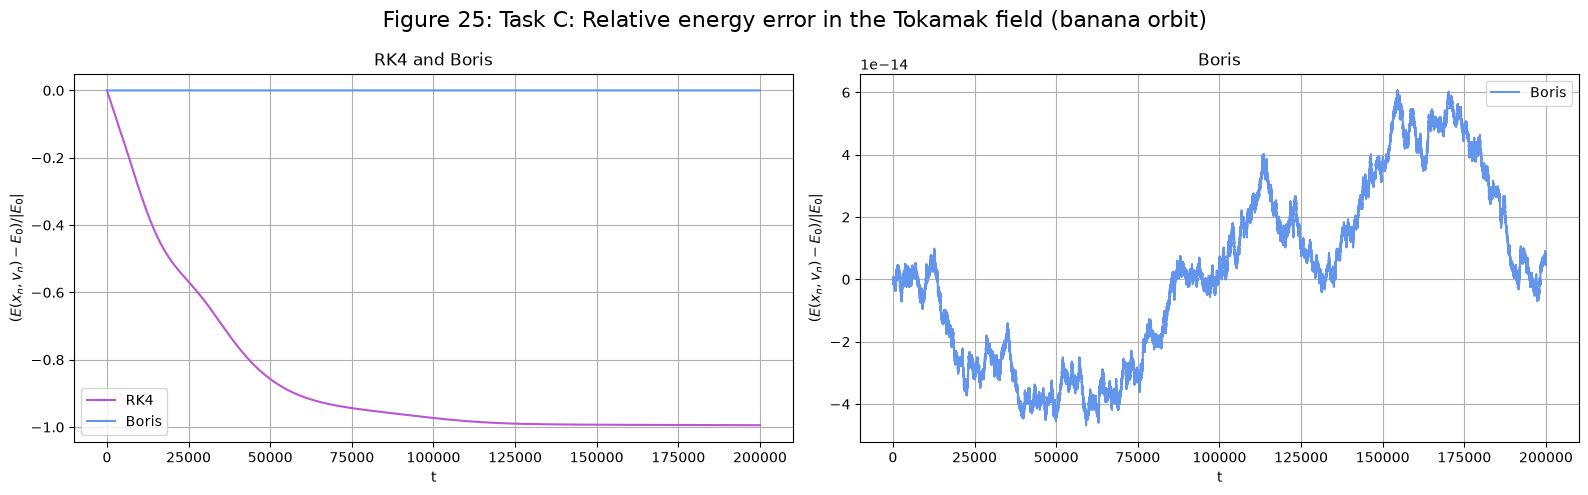

In [165]:
#Task C. relative energy error for banana orbit. (Fig. 7 in He et al. 2015)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

#both methods in the same plot
axes[0].plot(time_C, error_energy_tokamak, color="mediumorchid", label="RK4")
axes[0].plot(t_eval_c_boris, error_energy_tokamak_boris, color="cornflowerblue", label="Boris")
axes[0].set_title("RK4 and Boris")
axes[0].legend()

#boris alone, so the size of the error is visible
axes[1].plot(t_eval_c_boris, error_energy_tokamak_boris, color="cornflowerblue", label="Boris")
axes[1].set_title("Boris")
axes[1].legend()

for ax in axes:
    ax.set_xlabel("t")
    ax.set_ylabel(r"$(E(x_n, v_n) - E_0)/|E_0|$")
    ax.grid(True)

fig.suptitle("Figure 25: Task C: Relative energy error in the Tokamak field (banana orbit)", fontsize=16)
plt.tight_layout()
plt.show()


As in article 3, the relative energy error of the Boris method is constant, as can be seen from figure 25. The method preserves the energy exactly, with errors around machine precision level. This also shows that the energy for the RK4 actually decreases, leading to the effects discussed in the examination of figure 24 above. 